# APM1220 – Applied Multivariate Data Analysis

## Summative Assessment 1
### Multivariate Analysis of the Wine Quality Dataset

---

# 1. Assessment Overview

For this summative assessment, you will conduct a comprehensive multivariate analysis using the **Wine Quality Dataset** from the UCI Machine Learning Repository.

The dataset contains physicochemical measurements of Portuguese *Vinho Verde* wines. It includes separate red- and white-wine datasets, with **1,599 red wine samples** and **4,898 white wine samples**, for a combined total of **6,497 observations**. The dataset contains 11 physicochemical variables and a wine-quality score. The wine color variable identifies the samples as red or white.

* **Dataset source:** [UCI Machine Learning Repository — Wine Quality Dataset](https://archive.ics.uci.edu/dataset/186/wine+quality)

### Key Multivariate Techniques Applied

You will use the dataset to apply and integrate the following multivariate techniques:

1. **Multivariate Analysis of Variance (MANOVA)**
2. **Principal Component Analysis (PCA)**
3. **Exploratory Factor Analysis (EFA)**

> **Objective:** Demonstrate that you can move beyond simply running statistical procedures by formulating research questions, assessing statistical assumptions, performing multivariate analyses, interpreting results, and drawing meaningful conclusions from real-world data.

## 2. Dataset

Use the combined Wine Quality Dataset consisting of both red and white wines.

The dataset contains the following variables:

| Variable | Type | Description |
|---|---|---|
| `fixed acidity` | Continuous | Fixed acidity |
| `volatile acidity` | Continuous | Volatile acidity |
| `citric acid` | Continuous | Citric acid |
| `residual sugar` | Continuous | Residual sugar |
| `chlorides` | Continuous | Chloride concentration |
| `free sulfur dioxide` | Continuous | Free sulfur dioxide |
| `total sulfur dioxide` | Continuous | Total sulfur dioxide |
| `density` | Continuous | Density |
| `pH` | Continuous | pH |
| `sulphates` | Continuous | Sulphates |
| `alcohol` | Continuous | Alcohol concentration |
| `quality` | Integer | Sensory quality score |
| `color` | Categorical | Red or White |

The quality score ranges from **0 to 10** and is based on sensory evaluations. The UCI documentation identifies the physicochemical measurements as input variables and quality as the target variable.

> **Important:** For this assessment, do not treat `quality` as a continuous dependent variable in the MANOVA. The main multivariate analyses should focus on the physicochemical characteristics of the wines.

## 3. Research Scenario

You are a data analyst investigating the physicochemical characteristics of Portuguese *Vinho Verde* wines. The research team wants to answer three major questions:

### 3.1 Research Question 1 – MANOVA
> **Question:** Do red and white wines differ significantly in their overall physicochemical characteristics when several characteristics are considered simultaneously?

### 3.2 Research Question 2 – PCA
> **Question:** Can the 11 physicochemical measurements of wine be summarized using a smaller number of principal components while retaining a substantial proportion of the total variability?

### 3.3 Research Question 3 – EFA
> **Question:** What underlying latent dimensions or factors explain the relationships among the physicochemical characteristics of wine?

> **Note:** You may refine these questions slightly as long as your revised questions remain consistent with the required analyses.

---

In [2]:
import pandas as pd
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from statsmodels.multivariate.manova import MANOVA
from statsmodels.stats.outliers_influence import variance_inflation_factor
import os, warnings
from scipy import stats
from sklearn.decomposition import PCA

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 10})
pd.set_option('display.width', 200, 'display.max_columns', 30)
colors = {'Red': '#9b1c31', 'White': '#d4b83a'}

## 4. Part A – Data Preparation and Exploratory Analysis [15 points]

Before conducting MANOVA, PCA, and EFA, perform an appropriate exploratory analysis of the Wine Quality Dataset.

### Required Tasks

1. **Import** the red and white wine datasets.
2. **Combine** the datasets into one analytical dataset.
3. **Create or retain** a categorical variable identifying wine color (`Red` or `White`).
4. **Examine** the structure of the dataset.
5. **Determine** the number of observations and variables.
6. **Check** for missing values.
7. **Check** for duplicate observations.
8. **Examine** potential univariate and multivariate outliers.
9. **Compute** descriptive statistics for the quantitative variables.
10. **Examine** the distributions of the major physicochemical variables.
11. **Produce** an appropriate correlation matrix.
12. **Create** appropriate visualizations comparing red and white wines.

### Recommended Visualizations

You may use:
* **Histograms or density plots**
* **Boxplots** by wine color
* **Scatterplots**
* **Scatterplot matrix**
* **Correlation heatmap**

### Required Interpretation

Briefly discuss:
* **Which variables appear most variable?**
* **Which variables appear strongly correlated?**
* **Are there noticeable differences between red and white wines?**
* **Are there potential outliers or unusual observations?**
* **Are there variables that may require special consideration before PCA or EFA?**

In [3]:
# combining 2 datasets
red = pd.read_csv('/content/drive/MyDrive/DATASETS /Assessment Dataset/winequality-red.csv', sep=';')
white = pd.read_csv('/content/drive/MyDrive/DATASETS /Assessment Dataset/winequality-white.csv', sep=';')

red['wine_type'] = 'red'
white['wine_type'] = 'white'

wine = pd.concat([red, white], ignore_index= True)

wine.to_csv("winequality-merged.csv", index=False)

In [4]:
df = pd.read_csv('/content/drive/MyDrive/DATASETS /Assessment Dataset/winequality-merged.csv')
print(df.head())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  alcohol  quality wine_type
0            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0.56      9.4        5       red
1            7.8              0.88         0.00             2.6      0.098                 25.0                  67.0   0.9968  3.20       0.68      9.8        5       red
2            7.8              0.76         0.04             2.3      0.092                 15.0                  54.0   0.9970  3.26       0.65      9.8        5       red
3           11.2              0.28         0.56             1.9      0.075                 17.0                  60.0   0.9980  3.16       0.58      9.8        6       red
4            7.4              0.70         0.00             1.9      0.076                 11.0                  34.0   0.9978  3.51       0

In [5]:
# categorical variable for red and white variables

if 'wine_type' in df.columns and 'color' not in df.columns:
  df['color'] = df['wine_type'].str.capitalize()
elif 'color' in df.columns:
  df['color'] = df['color'].str.capitalize()

df['color'] = df['color'].astype('category')
print(df.dtypes)


fixed acidity            float64
volatile acidity         float64
citric acid              float64
residual sugar           float64
chlorides                float64
free sulfur dioxide      float64
total sulfur dioxide     float64
density                  float64
pH                       float64
sulphates                float64
alcohol                  float64
quality                    int64
wine_type                 object
color                   category
dtype: object


In [6]:
vars = [
    'fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
    'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
    'pH', 'sulphates', 'alcohol'
]

# checking the dataset
n_rows, n_cols = df.shape
missing_values = df.isnull().sum()
duplicates = df.duplicated().sum()
print('DATASET OVERVIEW: ')
print(f"Number of rows: {n_rows}")
print(f"Number of columns: {n_cols}")
print(f"Missing values: \n{missing_values}")
print(f"Duplicate observations: {duplicates}")
print('-'*30)

# descriptive statistics
overall_stats = df[vars].describe()
overall_stats.loc['skewness'] = df[vars].skew()
overall_stats.loc['kurtosis'] = df[vars].kurt()
overall_stats.loc['CV (%)'] = (overall_stats.loc['std'] / overall_stats.loc['mean']) * 100

print("OVERALL DESCRIPTIVE STATISTICS: ")
print(overall_stats.loc[['mean', 'std', 'min', '50%', 'max', 'skewness', 'kurtosis', 'CV (%)']].round(3))

grouped_stats = df.groupby('color')[vars].agg(['mean', 'std', 'median']).round(3)
print("GROUPED DESCRIPTIVE STATISTICS (RED VS WHITE): ")
print(grouped_stats)

DATASET OVERVIEW: 
Number of rows: 6497
Number of columns: 14
Missing values: 
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
color                   0
dtype: int64
Duplicate observations: 1177
------------------------------
OVERALL DESCRIPTIVE STATISTICS: 
          fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density     pH  sulphates  alcohol
mean              7.215             0.340        0.319           5.443      0.056               30.525               115.745    0.995  3.219      0.531   10.492
std               1.296             0.165        0.145           4.758      0.035               17.749                56.522    0

In [7]:
# detect any multivariate outliers

X = df[vars].values
mean_X = np.mean(X, axis=0)
cov_X = np.cov(X, rowvar=False)
inv_cov_X = np.linalg.inv(cov_X)

diff = X - mean_X
mahalanobis_dist = np.sum(np.dot(diff, inv_cov_X) * diff, axis=1)

chi2_cutoff = stats.chi2.ppf(1 - 0.001, df=len(vars))
mv_outliers = np.sum(mahalanobis_dist > chi2_cutoff)

print(f"\n=== MULTIVARIATE OUTLIER ANALYSIS ===")
print(f"Mahalanobis Cutoff (df=11, alpha=0.001): {chi2_cutoff:.3f}")
print(f"Multivariate Outliers Count: {mv_outliers} ({(mv_outliers/n_rows)*100:.2f}%)")


=== MULTIVARIATE OUTLIER ANALYSIS ===
Mahalanobis Cutoff (df=11, alpha=0.001): 31.264
Multivariate Outliers Count: 175 (2.69%)


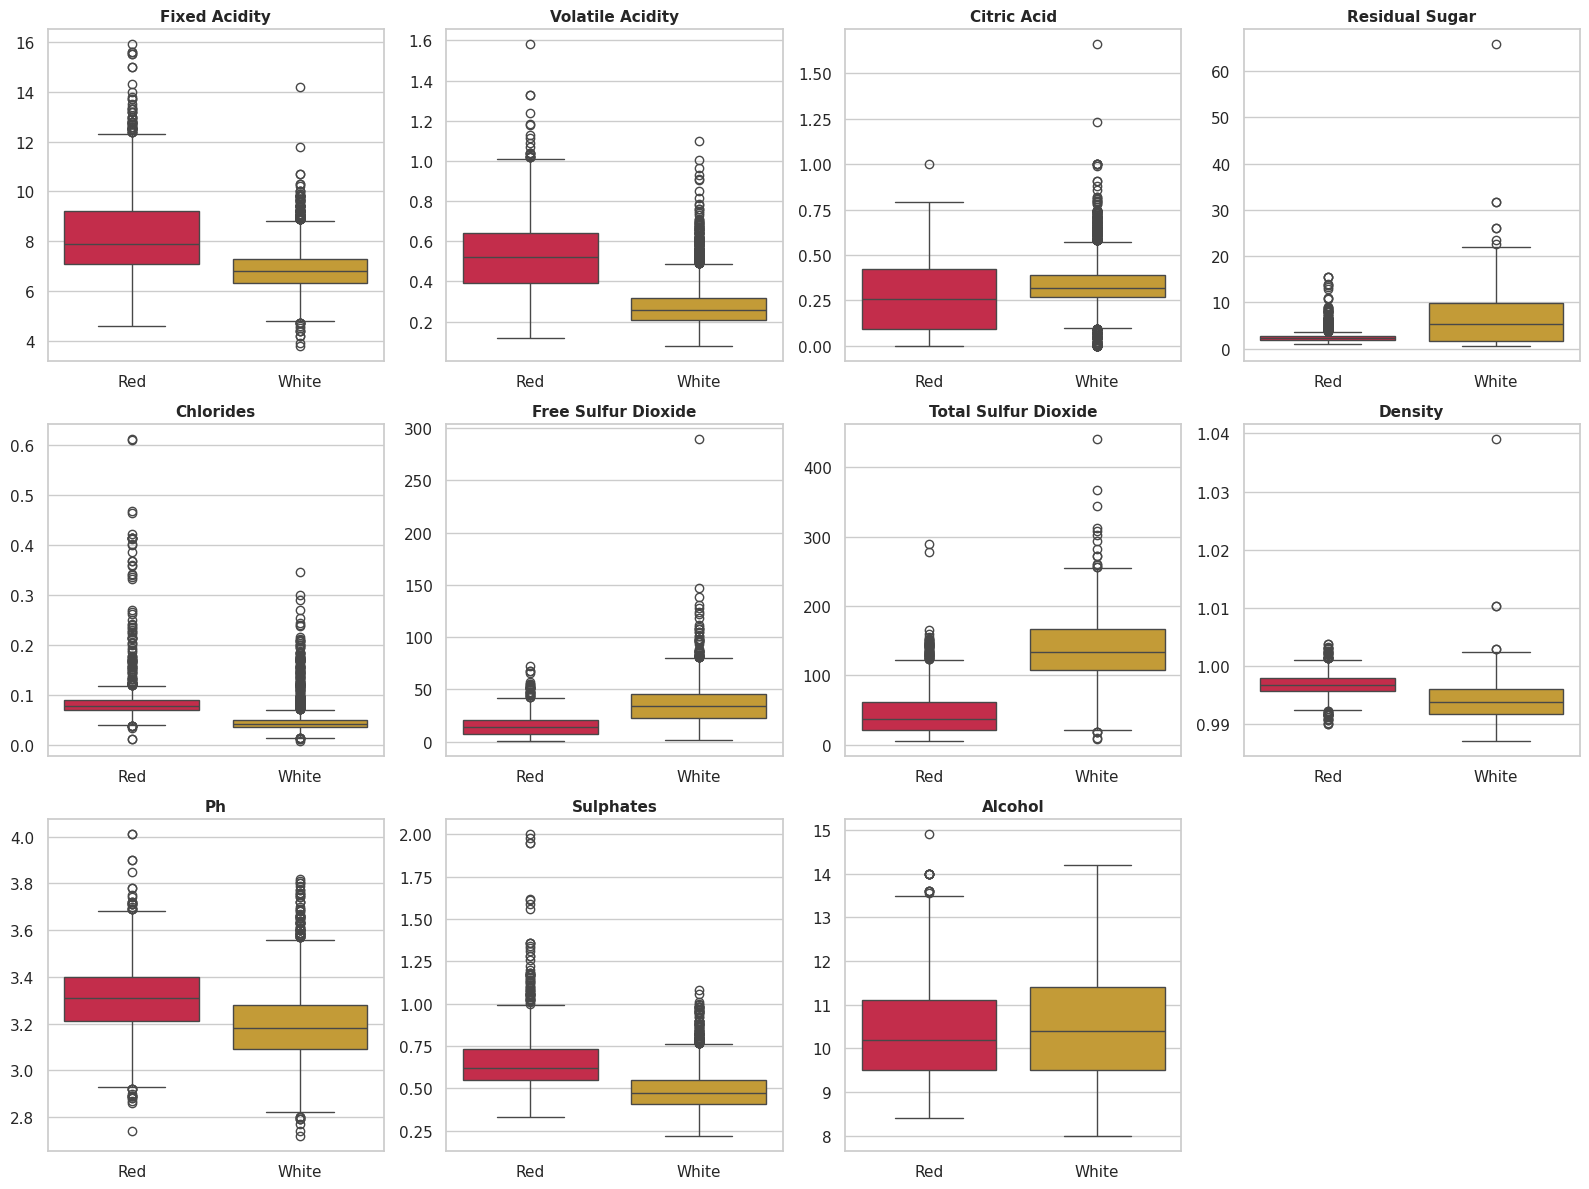

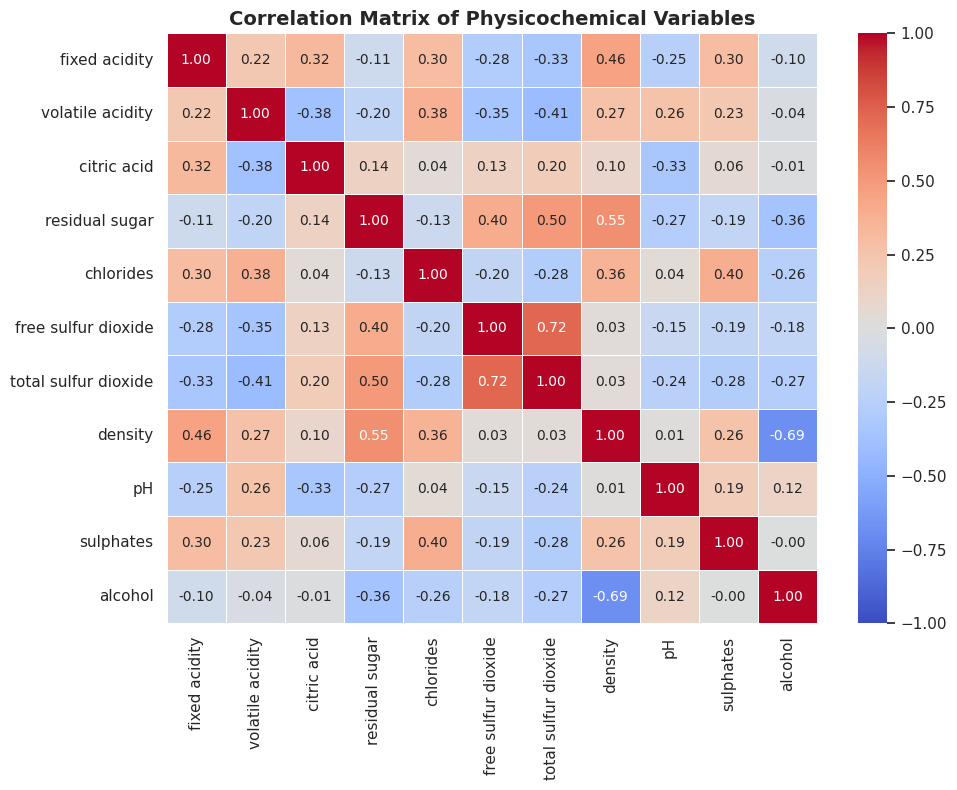

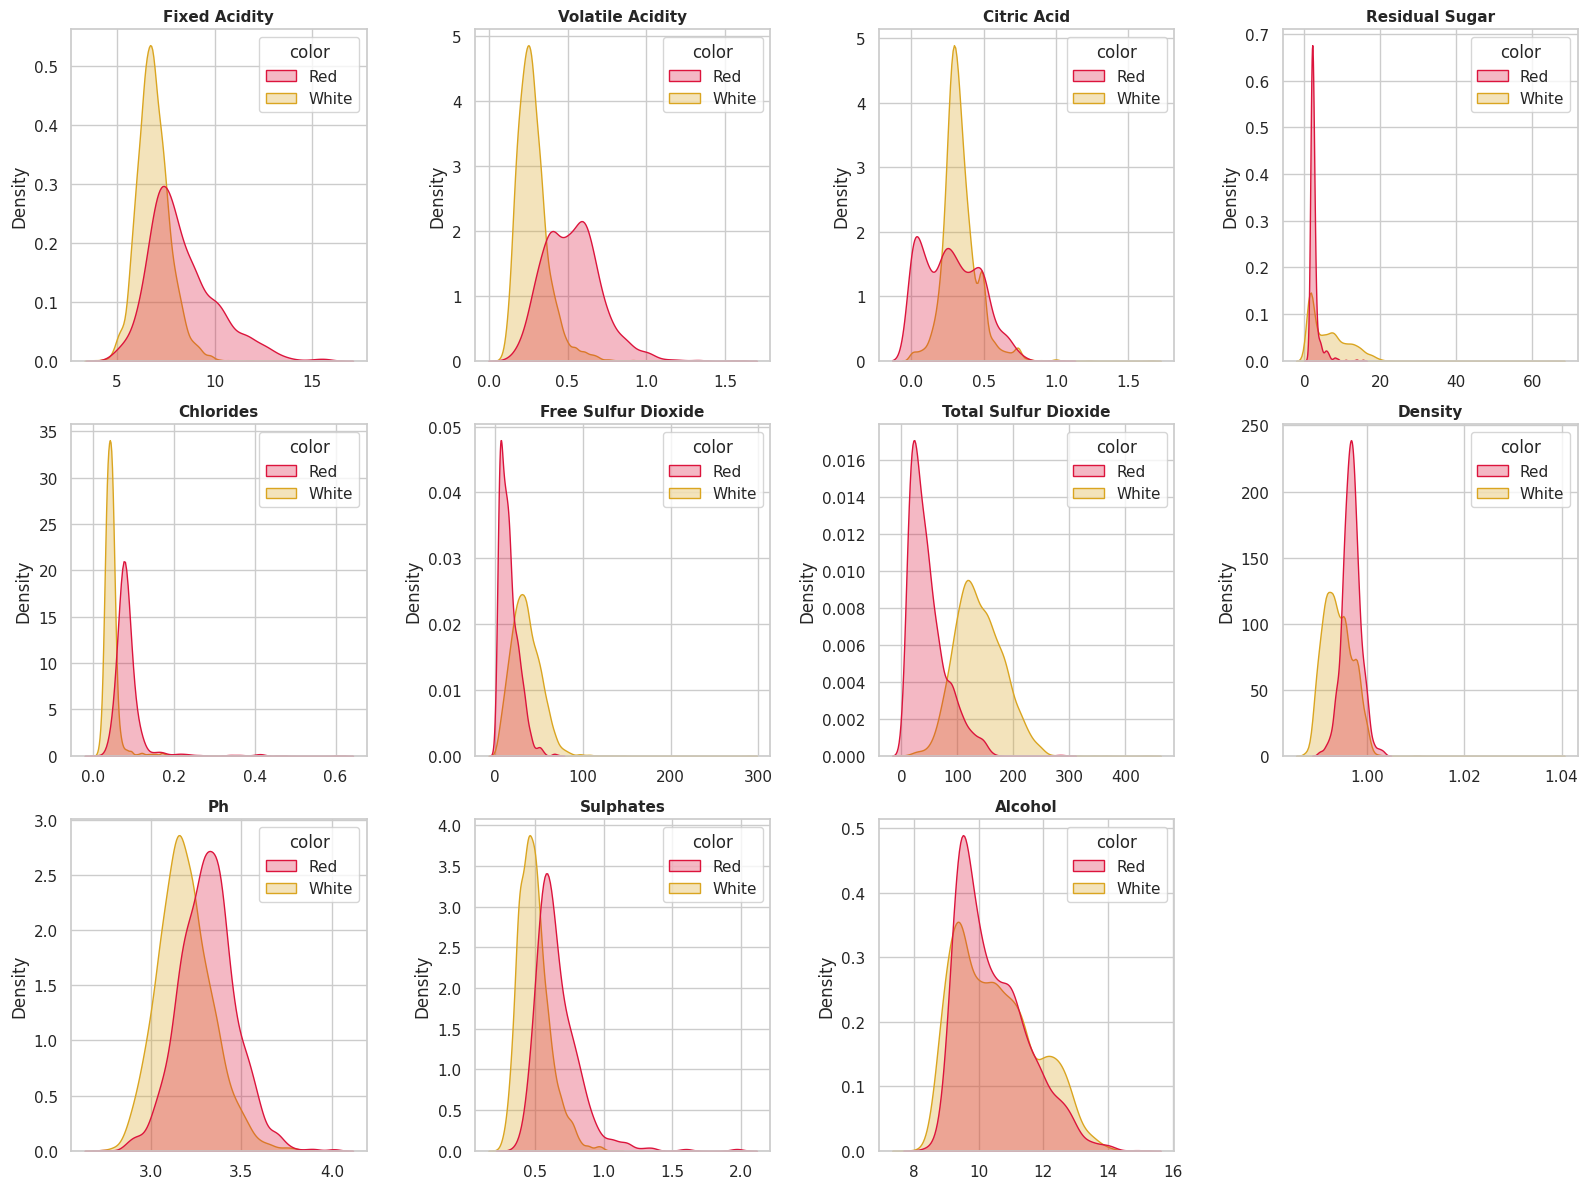

In [8]:
# 5. Correlation Matrix
corr_matrix = df[vars].corr()

# 6. Generating Required Visualizations
# Plot A: Boxplots by Wine Color
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(vars):
    sns.boxplot(x='color', y=col, data=df, ax=axes[i], palette={'Red': 'crimson', 'White': 'goldenrod'})
    axes[i].set_title(col.title(), fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')
    axes[i].set_ylabel('')

fig.delaxes(axes[11]) # Remove empty 12th panel
plt.tight_layout()
plt.savefig('boxplots_by_color.png', dpi=300)
plt.show()

# Plot B: Correlation Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlation Matrix of Physicochemical Variables', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=300)
plt.show

# Plot C: Density Distributions by Wine Color
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(vars):
    sns.kdeplot(data=df, x=col, hue='color', common_norm=False, ax=axes[i],
                palette={'Red': 'crimson', 'White': 'goldenrod'}, fill=True, alpha=0.3)
    axes[i].set_title(col.title(), fontsize=11, fontweight='bold')
    axes[i].set_xlabel('')

fig.delaxes(axes[11])
plt.tight_layout()
plt.savefig('density_plots_by_color.png', dpi=300)
plt.show()


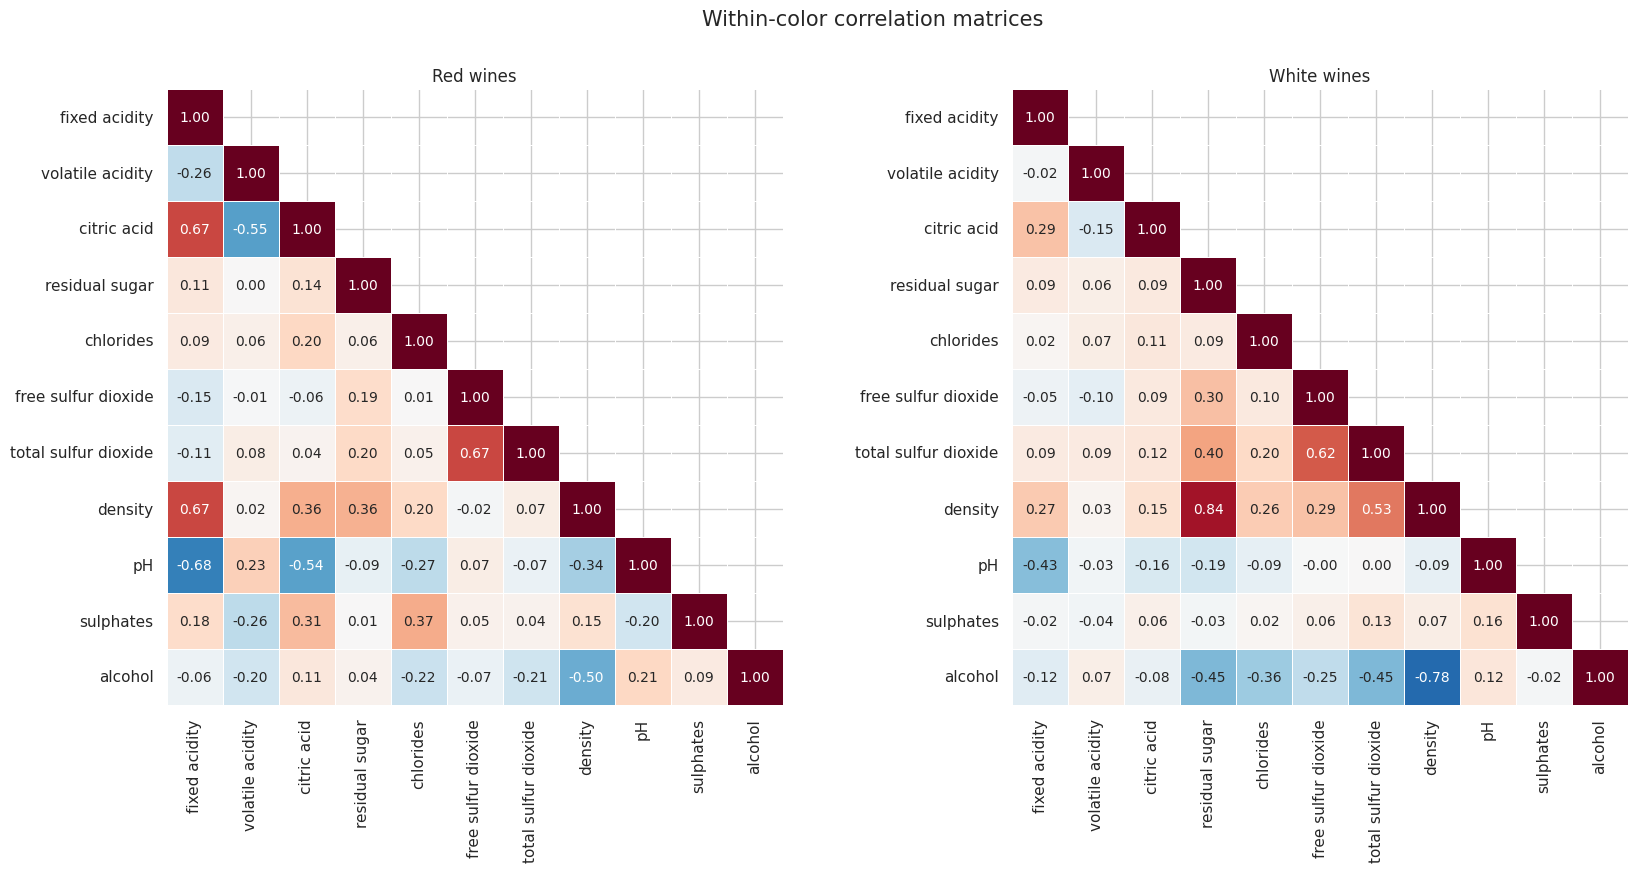

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, c in zip(axes, ['Red','White']):
    cc = df.loc[df.color==c, vars].corr()
    sns.heatmap(cc, mask=np.triu(np.ones_like(cc,bool),k=1), annot=True, fmt='.2f', cmap='RdBu_r',
                vmin=-1, vmax=1, square=True, linewidths=.5, cbar=False, ax=ax)
    ax.set_title(f'{c} wines')
plt.suptitle('Within-color correlation matrices', fontsize=15)
plt.show()

## Required Interpretation

**Dataset summary.** 6,497 wines (1,599 red, 4,898 white), 11 physicochemical variables plus `quality` and `color`. No missing values; 151 zeros in `citric acid` (plausible, not a placeholder). 1,177 rows (18.1%) are exact duplicates (240 red, 937 white); they are retained in the primary analysis because the data carry no wine ID and identical rounded lab values can come from different wines, and a de-duplicated copy is kept for sensitivity checks.

**1. Which variables appear most variable?**
In relative terms (coefficient of variation) `residual sugar` (CV ≈ 87%), `chlorides` (63%), `free sulfur dioxide` (58%), `total sulfur dioxide` (49%), `volatile acidity` (48%) and `citric acid` (46%) vary the most. `density` (0.3%) and `pH` (5%) vary the least. In absolute terms, the raw variances are on wildly different scales (total SO₂ SD ≈ 57 vs. density SD ≈ 0.003), so any covariance-based method must use standardized variables.

**2. Which variables are strongly correlated?**
Only three pairs reach |r| ≥ .50 overall: `free` and `total sulfur dioxide` (r = .72), `alcohol` and `density` (r = −.69), and `residual sugar` and `density` (r = .55). Moderate links (|r| ≈ .3–.5) include total SO₂ with residual sugar (.50) and volatile acidity (−.41), fixed acidity with density (.46), and citric acid with volatile acidity (−.38). Sixteen of 55 pairs have |r| ≥ .30, so there is enough shared structure for PCA/EFA, but the matrix is not extremely collinear (determinant = 0.0033, condition number = 92). Note that correlations change by color: density–sugar is r = .84 in white but only .36 in red, and density–alcohol is −.78 in white vs. −.50 in red.

**3. Are there noticeable differences between red and white wines?**
Yes, large ones. By Cohen's d: total SO₂ (white higher, |d| = 2.28), volatile acidity (red higher, 2.00), chlorides (red, 1.39), sulphates (red, 1.30), fixed acidity (red, 1.29), free SO₂ (white, 1.24), density (red, 0.99), residual sugar (white, 0.86) and pH (red, 0.81). Citric acid differs moderately (0.44) and alcohol barely at all (0.08). Red wines are more acidic and have higher chlorides and sulphates; white wines contain far more sulfur dioxide and sugar. This strongly anticipates a significant MANOVA, and the pattern of group differences suggests color will be a major source of variance in the PCA/EFA.

**4. Potential outliers or unusual observations.**
Univariate: `fixed acidity` (128 cases with |z| > 3), `chlorides` (107; max |z| = 15.8), `volatile acidity` (95) and `sulphates` (75) have the most extreme values. Multivariate (Mahalanobis D², χ²(11) cutoff = 31.26 at p < .001): 60 red (3.75%) and 137 white (2.80%) wines are flagged, which is above the 0.1% expected under multivariate normality, confirming heavy tails. A few cases are clearly suspicious: row 4380 (white; residual sugar = 65.8, density = 1.039, D² ≈ 1740), row 6344 (white; free SO₂ = 289, total SO₂ = 440) and two red wines with chlorides ≈ 0.61. These may be data-entry errors or genuinely unusual wines and should be handled explicitly (e.g., sensitivity analysis with and without them) rather than silently dropped.

**5. Variables needing special consideration before PCA/EFA.**
- *Skewness/non-normality:* `chlorides` (skew 5.4, excess kurtosis 50.9), `sulphates` (1.8), `fixed acidity` (1.7), `volatile acidity` (1.5), `residual sugar` (1.4) and `free SO₂` (1.2) are strongly right-skewed. Shapiro–Wilk rejects normality for every variable, and the D²–χ² Q-Q plots depart from the line. A log transform greatly reduces skew (chlorides 5.4 → 0.88, residual sugar 1.4 → 0.24, sulphates 1.8 → 0.40), so a transformed analysis is worth considering, especially for ML-based EFA.
- *Collinearity:* `density` has VIF = 15.9 (largely explained by alcohol and sugar) and `residual sugar` 7.2; `free` and `total SO₂` overlap strongly. These variables are likely to load together and dominate shared components/factors.
- *Scale:* use the correlation matrix (standardized variables) for PCA and EFA.
- *Group structure:* because red and white differ so much in mean and correlation structure, a pooled PCA/EFA will partly reflect the red/white contrast rather than within-color chemistry; consider reporting color-specific or color-centered solutions as a robustness check.
- *Unequal groups and outliers:* 1:3 group ratio and heavy tails also matter for MANOVA assumptions (Box's M, Mahalanobis) in Part B.

---

# 5. Part B – Multivariate Analysis of Variance (MANOVA) [30 points]

## Research Question
Do red and white wines differ significantly in their combined physicochemical characteristics?

### Variable Specifications
* **Independent Variable:** `color`
* **Groups:** Red vs. White
* **Dependent Variables:** Select at least four physicochemical variables based on exploratory data analysis and provide a justification for your selection.

*Example candidates to consider:*
* Fixed Acidity
* Volatile Acidity
* Residual Sugar
* Chlorides
* Density
* Sulphates
* Alcohol

> **Note:** Do not automatically select variables simply because they are available. Explain why your selected variables are appropriate for MANOVA.

## Required Tasks

### 1. State the Hypotheses
Clearly state the multivariate null and alternative hypotheses:

* $H_0$: The mean vector of the selected physicochemical variables is the same for red and white wines ($\boldsymbol{\mu}_{\text{red}} = \boldsymbol{\mu}_{\text{white}}$).
* $H_1$: The mean vectors differ between red and white wines ($\boldsymbol{\mu}_{\text{red}} \neq \boldsymbol{\mu}_{\text{white}}$).

### 2. Assess MANOVA Assumptions
Investigate appropriate statistical assumptions, including:
* **Independence of observations**
* **Multivariate normality**
* **Multivariate outliers**
* **Homogeneity of covariance matrices** (e.g., Box's M test)
* **Reasonable relationships among dependent variables** (avoiding extreme multicollinearity or singularity)

Use appropriate diagnostics and explain your findings.

### 3. Conduct the MANOVA
Report an appropriate multivariate test statistic (e.g., Wilks' $\Lambda$, Pillai's Trace, Hotelling's Trace, or Roy's Largest Root) including:
* **Test statistic value**
* **$F$-value**
* **Degrees of freedom ($df_{\text{num}}, df_{\text{den}}$)**
* **$p$-value**
* **Effect size** (e.g., partial $\eta^2$), where appropriate

### 4. Follow-Up Analyses
If the MANOVA is statistically significant, conduct appropriate follow-up analyses to determine which physicochemical variables contribute to the multivariate difference.

Report appropriate:
* **Univariate ANOVA results**
* **Effect sizes**
* **Post-hoc analysis**, if applicable

## Required Interpretation

Answer the core research question:
* **Are red and white wines significantly different when their physicochemical characteristics are considered simultaneously?**

> **Guidance:** Do not simply write *"The MANOVA was significant."* Explain what the result means in the context of wine chemistry (e.g., structural differences in acidity, fermentation residuals, or chemical profiles between wine types).

In [10]:
# assign wine to df which contains the added 'color' column
wine = df.copy()

# use underscores in column names so the MANOVA formula works
# we need to put "_" in order for the manove works. Manova doesn't read white spaces

wine.columns = [c.replace(' ', '_') for c in wine.columns]

all_vars = ['fixed_acidity', 'volatile_acidity', 'citric_acid', 'residual_sugar', 'chlorides',
            'free_sulfur_dioxide', 'total_sulfur_dioxide', 'density', 'pH', 'sulphates', 'alcohol']
print(wine.shape)
print(wine['color'].value_counts())

(6497, 14)
color
White    4898
Red      1599
Name: count, dtype: int64


## Step 1. Choose the dependent variables (DVs) and justify the choice
I use three things from the exploratory analysis (Part A):
1. **Effect size (Cohen's d):** does the variable differ clearly between red and white?
2. **VIF (collinearity):** is the variable almost a copy of other variables?
3. **Chemical meaning:** do the chosen variables cover different parts of wine chemistry?

In [11]:
red = wine[wine['color'] == 'Red']
white = wine[wine['color'] == 'White']

# Cohen's d = (mean_red - mean_white) / pooled standard deviation
pooled_sd = np.sqrt(((len(red)-1)*red[all_vars].var() + (len(white)-1)*white[all_vars].var()) / (len(red)+len(white)-2))
cohens_d = (red[all_vars].mean() - white[all_vars].mean()) / pooled_sd

# VIF using all 11 variables (standardized)
z = (wine[all_vars] - wine[all_vars].mean()) / wine[all_vars].std()
vif = [variance_inflation_factor(np.c_[np.ones(len(z)), z.values], i+1) for i in range(len(all_vars))]

selection = pd.DataFrame({'Cohens_d': cohens_d.round(2),
                          'abs_d': cohens_d.abs().round(2),
                          'VIF_all_11': np.round(vif, 2),
                          'skew': wine[all_vars].skew().round(2)})
selection.sort_values('abs_d', ascending=False)

,Cohens_d,abs_d,VIF_all_11,skew
total_sulfur_dioxide,-2.28,2.28,2.94,-0.00
volatile_acidity,2.00,2.00,1.95,1.50
chlorides,1.39,1.39,1.63,5.40
sulphates,1.30,1.30,1.54,1.80
fixed_acidity,1.29,1.29,4.90,1.72
free_sulfur_dioxide,-1.24,1.24,2.14,1.22
density,0.99,0.99,15.91,0.50
residual_sugar,-0.86,0.86,7.23,1.44
pH,0.81,0.81,2.54,0.39
citric_acid,-0.44,0.44,1.61,0.47


In [12]:
# Selected DVs
dvs = ['fixed_acidity', 'volatile_acidity', 'residual_sugar', 'chlorides', 'sulphates', 'total_sulfur_dioxide']

# Check that the chosen set is NOT highly collinear (VIF on the 6 chosen variables only)
zs = (wine[dvs] - wine[dvs].mean()) / wine[dvs].std()
vif_dvs = pd.Series([variance_inflation_factor(np.c_[np.ones(len(zs)), zs.values], i+1) for i in range(len(dvs))], index=dvs)
print('VIF within the selected DVs:'); print(vif_dvs.round(2).to_string())

VIF within the selected DVs:
fixed_acidity           1.22
volatile_acidity        1.33
residual_sugar          1.34
chlorides               1.36
sulphates               1.27
total_sulfur_dioxide    1.68


**Selection and reasons**

| Variable | Decision | Reason |
|---|---|---|
| fixed acidity | **Keep** | Large difference (d = 1.29); represents the wine's acid structure |
| volatile acidity | **Keep** | Large difference (d = 2.00); relates to fermentation/spoilage character |
| residual sugar | **Keep** | Large difference (d = −0.86); sugar left after fermentation |
| chlorides | **Keep** | Large difference (d = 1.39); mineral/salt content |
| sulphates | **Keep** | Large difference (d = 1.30); preservative/antimicrobial additive |
| total sulfur dioxide | **Keep** | Largest difference (d = −2.28); preservative level. I use *total* only (not free) because the two are strongly correlated (r = .72) |
| density | Drop | VIF = 15.9, mostly a mix of alcohol and sugar, so it adds redundancy rather than new information |
| alcohol | Drop | Almost no difference between colors (d = 0.08) and it is tied to density (r = −.69) |
| free SO₂ | Drop | Redundant with total SO₂ |
| citric acid, pH | Drop | Smaller differences, and pH/acidity are already covered by the acid variables |

The six chosen variables come from different areas of chemistry (acidity, sugar, salts, preservatives), and none has a VIF above about 2, so there is no extreme multicollinearity.

## Step 2. Hypotheses

- **H₀:** the mean vector of the six variables is the same for red and white wines, **μ_red = μ_white**.
- **H₁:** the mean vectors differ, **μ_red ≠ μ_white** (at least one variable differs).
- Significance level: α = .05.

## Step 3. Check the assumptions

### 3.1 Independence of observations

In [13]:
# Independence cannot be tested with a statistic. It is a design question.
# What we CAN check is whether repeated rows could break it:
n_dup = wine.duplicated(subset=dvs + ['color']).sum()
print('Rows that repeat the same values on the 6 DVs within the data:', n_dup)
print('Share of the data:', round(100 * n_dup / len(wine), 1), '%')

Rows that repeat the same values on the 6 DVs within the data: 1192
Share of the data: 18.3 %


Each row is a separate wine sample, and no wine ID or batch/producer variable is available. Samples from the same producer or
vintage could be correlated, which we cannot check. Repeated rows might also be the same wine measured more than once. As a safeguard,
I repeat the MANOVA without duplicates in Step 6.

### 3.2 Multivariate outliers (Mahalanobis distance within each color)

In [14]:
cutoff = stats.chi2.ppf(0.999, df=len(dvs))     # p < .001 rule
wine['D2'] = np.nan

for c in ['Red', 'White']:
    X = wine.loc[wine['color'] == c, dvs]
    diff = X - X.mean()
    inv_cov = np.linalg.inv(X.cov())
    wine.loc[wine['color'] == c, 'D2'] = np.einsum('ij,jk,ik->i', diff.values, inv_cov, diff.values)

wine['outlier'] = wine['D2'] > cutoff
print('Chi-square cutoff (df=6, p<.001):', round(cutoff, 2))
print(wine.groupby('color')['outlier'].agg(['sum', 'mean']).rename(columns={'sum': 'n_outliers', 'mean': 'share'}).round(3))

Chi-square cutoff (df=6, p<.001): 22.46
       n_outliers  share
color                   
Red            55  0.034
White         121  0.025


### 3.3 Multivariate normality (Mardia's tests, each group)

In [15]:
def mardia(X):
    # Mardia's skewness and kurtosis tests for multivariate normality
    X = np.asarray(X, float)
    n, p = X.shape
    diff = X - X.mean(axis=0)
    S = np.cov(X, rowvar=False, bias=True)          # covariance divided by n
    G = diff @ np.linalg.inv(S) @ diff.T            # n x n matrix
    skew_stat = (G ** 3).sum() / (n * 6)            # n * b1p / 6
    skew_p = 1 - stats.chi2.cdf(skew_stat, p * (p + 1) * (p + 2) / 6)
    b2 = (np.diag(G) ** 2).mean()                   # multivariate kurtosis
    kurt_z = (b2 - p * (p + 2)) / np.sqrt(8 * p * (p + 2) / n)
    kurt_p = 2 * (1 - stats.norm.cdf(abs(kurt_z)))
    return {'n': n, 'skew_stat': round(skew_stat, 1), 'skew_p': skew_p,
            'kurtosis': round(b2, 1), 'kurtosis_expected': p * (p + 2), 'kurt_z': round(kurt_z, 1), 'kurt_p': kurt_p}

mvn = pd.DataFrame({c: mardia(wine.loc[wine['color'] == c, dvs]) for c in ['Red', 'White']}).T
mvn

,n,skew_stat,skew_p,kurtosis,kurtosis_expected,kurt_z,kurt_p
Red,1599.0,17850.6,0.0,144.0,48.0,195.9,0.0
White,4898.0,28080.7,0.0,106.0,48.0,207.0,0.0


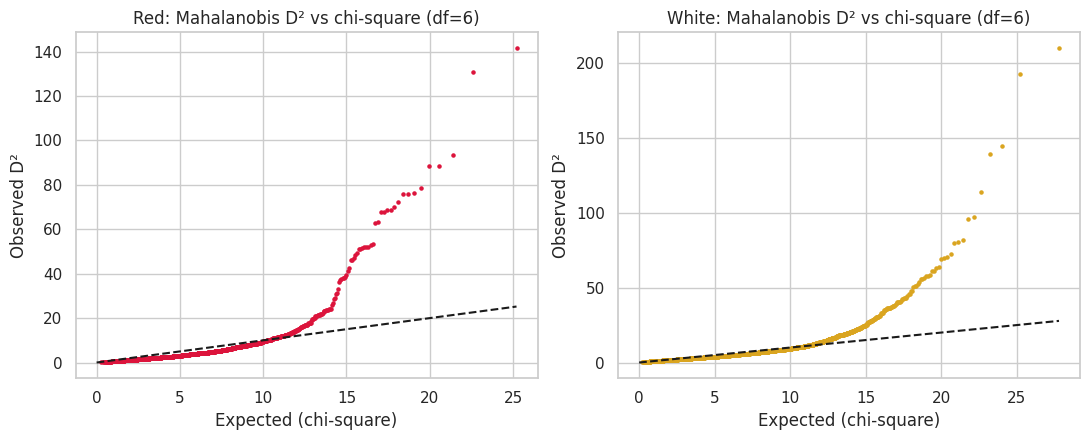

In [16]:
# Q-Q plot of Mahalanobis distances against chi-square quantiles
color_dict = {'Red': 'crimson', 'White': 'goldenrod'}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, c in zip(axes, ['Red', 'White']):
    d2 = np.sort(wine.loc[wine['color'] == c, 'D2'].values)
    q = stats.chi2.ppf((np.arange(1, len(d2)+1) - 0.5) / len(d2), df=len(dvs))
    ax.scatter(q, d2, s=5, color=color_dict[c])
    ax.plot([0, q.max()], [0, q.max()], 'k--')
    ax.set_title(f'{c}: Mahalanobis D² vs chi-square (df=6)')
    ax.set_xlabel('Expected (chi-square)')
    ax.set_ylabel('Observed D²')

plt.tight_layout()
plt.savefig('B1_mvn_qq.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.4 Homogeneity of covariance matrices (Box's M) and univariate Levene tests

In [17]:
def box_m(groups):
    # groups = list of data frames (one per group)
    g = len(groups)
    p = groups[0].shape[1]
    n = np.array([len(x) for x in groups])
    covs = [x.cov().values for x in groups]
    pooled = sum((n[i]-1) * covs[i] for i in range(g)) / (n.sum() - g)
    M = (n.sum() - g) * np.log(np.linalg.det(pooled)) - sum((n[i]-1) * np.log(np.linalg.det(covs[i])) for i in range(g))
    c = (sum(1/(n-1)) - 1/(n.sum()-g)) * (2*p**2 + 3*p - 1) / (6 * (p+1) * (g-1))
    chi2 = M * (1 - c)
    df = (g-1) * p * (p+1) / 2
    return chi2, df, 1 - stats.chi2.cdf(chi2, df)

chi2_val, df_val, p_val = box_m([red[dvs], white[dvs]])
print(f"Box's M: chi-square = {chi2_val:.1f}, df = {df_val:.0f}, p = {p_val:.4g}")

print('\nLevene test for equal variances (each DV):')
lev = pd.DataFrame({v: stats.levene(red[v], white[v], center='median')[:2] for v in dvs}, index=['W', 'p']).T
lev['SD_red'] = red[dvs].std().round(3); lev['SD_white'] = white[dvs].std().round(3)
lev

Box's M: chi-square = 7222.4, df = 21, p = 0

Levene test for equal variances (each DV):


,W,p,SD_red,SD_white
fixed_acidity,942.329415,2.332510e-193,1.741,0.844
volatile_acidity,851.875126,4.419910e-176,0.179,0.101
residual_sugar,1867.543958,0.000000e+00,1.410,5.072
chlorides,123.968817,1.549289e-28,0.047,0.022
sulphates,107.742993,4.799569e-25,0.170,0.114
total_sulfur_dioxide,181.381178,8.506549e-41,32.895,42.498


Box's M is very sensitive with large samples, so it almost always rejects. What matters more is the group sizes and **how** the
covariances differ. The groups are unequal (1,599 vs 4,898), which is the situation where unequal covariances can distort the
test. I therefore use **Pillai's trace** (the most robust of the four statistics) and add a permutation test in Step 6.

### 3.5 Relationships among the DVs (multicollinearity / singularity)

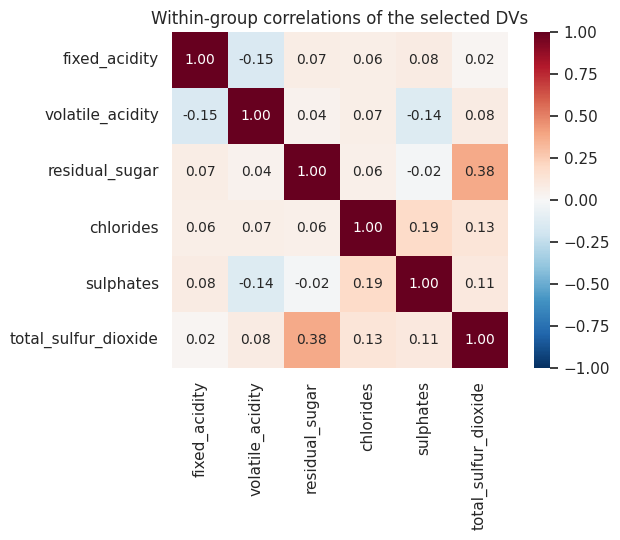

Determinant of within-group correlation matrix: 0.7471 (0 would mean singular)
Largest |r| between two DVs: 0.38


In [18]:
# Pooled within-group correlation (removes the red/white difference first)
centered = wine[dvs] - wine.groupby('color')[dvs].transform('mean')
within_corr = centered.corr()

plt.figure(figsize=(7, 5.5))
sns.heatmap(within_corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True)
plt.title('Within-group correlations of the selected DVs')
plt.tight_layout()
plt.show()
print('Determinant of within-group correlation matrix:', round(np.linalg.det(within_corr), 4), '(0 would mean singular)')
print('Largest |r| between two DVs:', round(within_corr.where(~np.eye(len(dvs), dtype=bool)).abs().max().max(), 2))

## Step 4. Run the MANOVA

In [19]:
formula = ' + '.join(dvs) + ' ~ color'
manova = MANOVA.from_formula(formula, data=wine)
result = manova.mv_test()
print(result.results['color']['stat'].round(4))
print('\nNote: a p-value shown as 0.0 means p < .001')

                           Value Num DF  Den DF      F Value Pr > F
Wilks' lambda           0.237027      6  6490.0  3481.814411    0.0
Pillai's trace          0.762973    6.0  6490.0  3481.814411    0.0
Hotelling-Lawley trace  3.218935      6  6490.0  3481.814411    0.0
Roy's greatest root     3.218935      6    6490  3481.814411    0.0

Note: a p-value shown as 0.0 means p < .001


In [20]:
# Tidy table of the four test statistics
stat_table = result.results['color']['stat'].round(4)
stat_table.index.name = 'test'
stat_table

,Value,Num DF,Den DF,F Value,Pr > F
test,,,,,
Wilks' lambda,0.237027,6,6490.0,3481.814411,0.0
Pillai's trace,0.762973,6.0,6490.0,3481.814411,0.0
Hotelling-Lawley trace,3.218935,6,6490.0,3481.814411,0.0
Roy's greatest root,3.218935,6,6490,3481.814411,0.0


In [21]:
# Effect size: with 2 groups, partial eta-squared = 1 - Wilks' Lambda (= Pillai's trace)
wilks = result.results['color']['stat'].loc["Wilks' lambda", 'Value']
pillai = result.results['color']['stat'].loc["Pillai's trace", 'Value']
print("Wilks' Lambda:", round(wilks, 4))
print("Pillai's trace:", round(pillai, 4))
print('Multivariate partial eta-squared =', round(1 - wilks, 3), f'({100*(1-wilks):.1f}% of the multivariate variance is explained by color)')

Wilks' Lambda: 0.237
Pillai's trace: 0.763
Multivariate partial eta-squared = 0.763 (76.3% of the multivariate variance is explained by color)


## Step 5. Follow-up analyses
Because the MANOVA is significant, I look at **which variables** drive the difference.
Two groups only → a post-hoc test such as Tukey is **not needed** (there is only one pair to compare).

### 5.1 Univariate ANOVAs, effect sizes and Welch test (Bonferroni α = .05 / 6 = .0083)

In [22]:
alpha_adj = 0.05 / len(dvs)
rows = []
for v in dvs:
    f, p = stats.f_oneway(red[v], white[v])                            # classic ANOVA
    welch_t, welch_p = stats.ttest_ind(red[v], white[v], equal_var=False)   # Welch (unequal variances)
    ss_between = len(red)*(red[v].mean()-wine[v].mean())**2 + len(white)*(white[v].mean()-wine[v].mean())**2
    ss_total = ((wine[v]-wine[v].mean())**2).sum()
    rows.append({'variable': v,
                 'mean_red': red[v].mean(), 'mean_white': white[v].mean(),
                 'F(1, 6495)': f, 'p': p, 'Welch_p': welch_p,
                 'eta_sq': ss_between / ss_total,
                 'cohens_d': (red[v].mean()-white[v].mean()) / np.sqrt(((len(red)-1)*red[v].var()+(len(white)-1)*white[v].var())/(len(wine)-2))})

anova = pd.DataFrame(rows).set_index('variable')
anova['significant (Bonferroni)'] = np.where(anova['p'] < alpha_adj, 'Yes', 'No')
anova['p'] = anova['p'].apply(lambda x: '<.001' if x < .001 else round(x, 3))
anova['Welch_p'] = anova['Welch_p'].apply(lambda x: '<.001' if x < .001 else round(x, 3))
anova.round(3).sort_values('eta_sq', ascending=False)

,mean_red,mean_white,"F(1, 6495)",p,Welch_p,eta_sq,cohens_d,significant (Bonferroni)
variable,,,,,,,,
total_sulfur_dioxide,46.468,138.361,6252.796,<.001,<.001,0.491,-2.278,Yes
volatile_acidity,0.528,0.278,4829.317,<.001,<.001,0.426,2.002,Yes
chlorides,0.087,0.046,2315.829,<.001,<.001,0.263,1.386,Yes
fixed_acidity,8.320,6.855,2016.510,<.001,<.001,0.237,1.293,Yes
sulphates,0.658,0.490,2021.708,<.001,<.001,0.237,1.295,Yes
residual_sugar,2.539,6.391,899.766,<.001,<.001,0.122,-0.864,Yes


### 5.2 Which variables separate the groups *together*? (discriminant function)

In [23]:
# With 2 groups the MANOVA has one discriminant function: w = (pooled covariance)^-1 x (mean difference)
n_r, n_w = len(red), len(white)
pooled_cov = ((n_r-1)*red[dvs].cov() + (n_w-1)*white[dvs].cov()) / (n_r + n_w - 2)
mean_diff = red[dvs].mean() - white[dvs].mean()

w = np.linalg.solve(pooled_cov.values, mean_diff.values)
sd = np.sqrt(np.diag(pooled_cov))
std_coef = w * sd                                    # standardized coefficients (unique contribution)
score_var = w @ pooled_cov.values @ w
structure_r = (pooled_cov.values @ w) / (sd * np.sqrt(score_var))   # correlation of each DV with the function

disc = pd.DataFrame({'standardized_coef': std_coef, 'structure_r': structure_r}, index=dvs)
disc['abs_coef'] = disc['standardized_coef'].abs()
print('Mahalanobis distance between group centroids D =', round(np.sqrt(mean_diff.values @ w), 2), 'SDs')
disc.sort_values('abs_coef', ascending=False).drop(columns='abs_coef').round(3)

Mahalanobis distance between group centroids D = 4.16 SDs


,standardized_coef,structure_r
total_sulfur_dioxide,-2.804,-0.547
volatile_acidity,2.603,0.481
sulphates,1.597,0.311
fixed_acidity,1.534,0.311
chlorides,1.175,0.333
residual_sugar,-0.078,-0.207


### 5.3 Figures

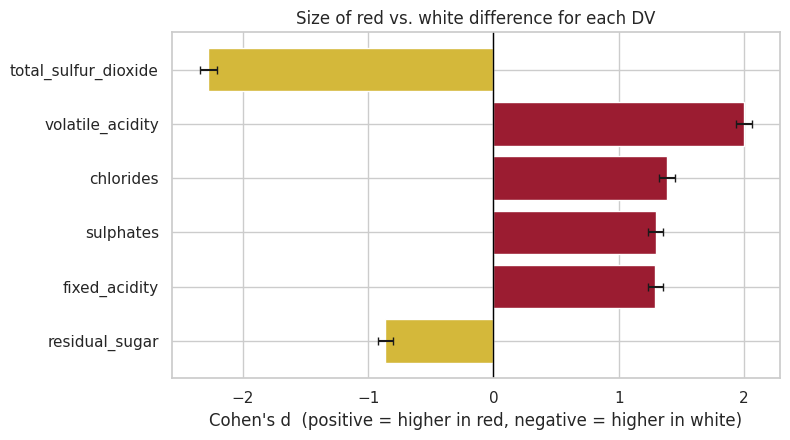

In [24]:
# (a) Effect sizes with 95% confidence intervals
d = anova['cohens_d']
se = np.sqrt((n_r+n_w)/(n_r*n_w) + d**2/(2*(n_r+n_w)))
order = d.abs().sort_values().index

plt.figure(figsize=(8, 4.5))
plt.barh(order, d[order], xerr=1.96*se[order], color=['#9b1c31' if x > 0 else '#d4b83a' for x in d[order]], capsize=3)
plt.axvline(0, color='black', lw=1)
plt.xlabel("Cohen's d  (positive = higher in red, negative = higher in white)")
plt.title('Size of red vs. white difference for each DV')
plt.tight_layout()
plt.show()

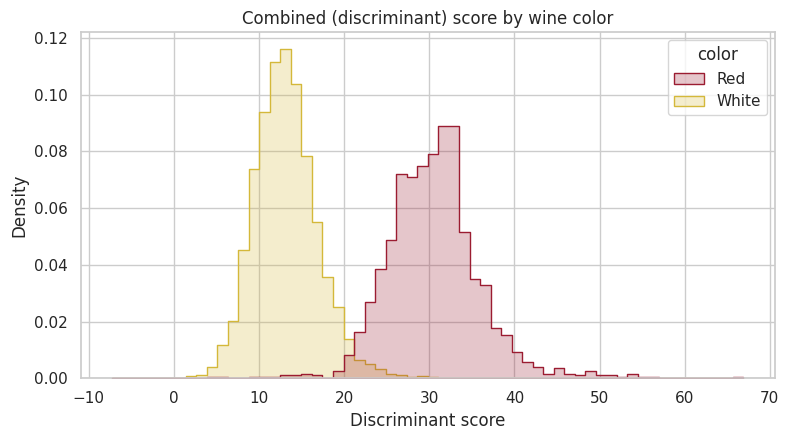

Classification accuracy using this single combined score: 97.8 %


In [25]:
# (b) Discriminant scores: how well does the combined chemistry separate red from white?
wine['disc_score'] = wine[dvs].values @ w      # one combined score per wine
plt.figure(figsize=(8, 4.5))
sns.histplot(data=wine, x='disc_score', hue='color', palette=colors, stat='density', common_norm=False, bins=60, element='step')
plt.title('Combined (discriminant) score by wine color')
plt.xlabel('Discriminant score')
plt.tight_layout()
plt.show()

# How accurately would the score classify wines? (simple cutoff halfway between the group means)
cut_score = (wine.loc[wine.color=='Red','disc_score'].mean() + wine.loc[wine.color=='White','disc_score'].mean()) / 2
pred = np.where(wine['disc_score'] > cut_score, 'Red', 'White')
print('Classification accuracy using this single combined score:', round((pred == wine['color']).mean() * 100, 1), '%')

## Step 6. Robustness checks
Because the assumptions (normality, equal covariances, outliers, duplicates) are not perfectly met, I repeat the MANOVA under four alternative settings.
If the conclusion never changes, it is robust.

In [26]:
def run_manova(data, variables):
    # returns Pillai's trace, F, df and p for color
    res = MANOVA.from_formula(' + '.join(variables) + ' ~ color', data=data).mv_test().results['color']['stat']
    row = res.loc["Pillai's trace"]
    return {'n': len(data), 'Pillai': row['Value'], 'F': row['F Value'], 'df_num': row['Num DF'], 'df_den': row['Den DF'], 'p': row['Pr > F']}

checks = {}

# 1. Original data
checks['1. Original data'] = run_manova(wine, dvs)

# 2. Log-transformed DVs (reduces skewness)
logged = wine.copy()
logged[dvs] = np.log(logged[dvs])
checks['2. Log-transformed DVs'] = run_manova(logged, dvs)

# 3. Duplicate rows removed
checks['3. Duplicates removed'] = run_manova(wine.drop_duplicates(subset=dvs + ['color']), dvs)

# 4. Multivariate outliers removed
checks['4. Outliers removed (D2 > cutoff)'] = run_manova(wine[~wine['outlier']], dvs)

robust = pd.DataFrame(checks).T
robust['p'] = robust['p'].apply(lambda x: '<.001' if x < .001 else round(x, 3))
robust.round(3)

,n,Pillai,F,df_num,df_den,p
1. Original data,6497.0,0.763,3481.814,6.0,6490.0,<.001
2. Log-transformed DVs,6497.0,0.807,4525.621,6.0,6490.0,<.001
3. Duplicates removed,5305.0,0.756,2732.985,6.0,5298.0,<.001
4. Outliers removed (D2 > cutoff),6321.0,0.814,4600.254,6.0,6314.0,<.001


In [27]:
# 5. Permutation test: shuffle the color labels many times and see how often a result as large as ours appears.
# (needs no normality or equal-covariance assumption). Statistic = Hotelling's T-squared.
def hotelling_t2(X, labels):
    a, b = X[labels == 'Red'], X[labels == 'White']
    diff = a.mean(axis=0) - b.mean(axis=0)
    sp = ((len(a)-1)*np.cov(a, rowvar=False) + (len(b)-1)*np.cov(b, rowvar=False)) / (len(a)+len(b)-2)
    return diff @ np.linalg.solve(sp, diff) * len(a) * len(b) / (len(a) + len(b))

X = wine[dvs].values
labels = wine['color'].values
observed = hotelling_t2(X, labels)

rng = np.random.default_rng(123)
perm = np.array([hotelling_t2(X, rng.permutation(labels)) for _ in range(2000)])

print('Observed T-squared =', round(observed, 1))
print('Largest T-squared in 2,000 random shuffles =', round(perm.max(), 1))
print('Permutation p-value =', (np.sum(perm >= observed) + 1) / (2000 + 1))

Observed T-squared = 20907.0
Largest T-squared in 2,000 random shuffles = 22.1
Permutation p-value = 0.0004997501249375312


## Results summary and interpretation

**Hypotheses.** H₀: μ_red = μ_white vs. H₁: μ_red ≠ μ_white on six variables (fixed acidity, volatile acidity, residual sugar, chlorides, sulphates, total sulfur dioxide).

**Assumptions (Step 3)**

| Assumption | Finding | Consequence |
|---|---|---|
| Independence | Cannot be tested. No wine ID or producer variable, and 18.3% of rows repeat the same DV values. | Repeated the analysis without duplicates (Step 6). |
| Multivariate outliers | 176 wines (55 red, 121 white; 2.7%) exceed the D² cutoff of 22.46 (p < .001). | Repeated the analysis without them (Step 6). |
| Multivariate normality | **Violated.** Mardia skewness and kurtosis both p < .001 in each group. Kurtosis is 144 (red) and 106 (white) against 48 expected. The Q–Q plots curve away from the line (heavy right tail). | Rely on Pillai's trace, log-transformed and permutation checks (Step 6). |
| Equal covariance matrices | **Violated.** Box's M χ²(21) = 7,222.4, p < .001; Levene p < .001 for every DV (e.g. residual sugar SD 1.41 red vs 5.07 white). Group sizes are also unequal (1:3). | Box's M is very sensitive at this sample size, so I used Pillai's trace (most robust statistic) and a permutation test that does not assume equal covariances. |
| No multicollinearity | **Met.** Largest within-group |r| = .38, determinant = .75, VIF ≤ 1.7. | No problem. The DV set is not redundant or singular. |

**MANOVA (Step 4).** Wilks' Λ = .237, Pillai's trace = .763, F(6, 6490) = 3,481.8, p < .001, multivariate partial η² = .76 (large).
With two groups all four test statistics give the same F and p. I report Pillai's trace as the primary statistic because of the assumption violations.

**Follow-up (Step 5).** All six univariate ANOVAs are significant after a Bonferroni correction (α = .0083), and the Welch tests agree.
Ranked by η²: total sulfur dioxide (.49, white higher), volatile acidity (.43, red higher), chlorides (.26, red), fixed acidity (.24, red), sulphates (.24, red), residual sugar (.12, white).
Post-hoc tests such as Tukey are not applicable because there are only two groups.
The discriminant function shows each variable's *unique* contribution: total SO₂ (−2.80) and volatile acidity (+2.60) dominate, followed by sulphates (1.60), fixed acidity (1.53) and chlorides (1.18).
Residual sugar has a large univariate effect but almost no unique contribution (−0.08), so its difference is largely shared with the other variables, especially total SO₂.

**Robustness (Step 6).** The conclusion does not change under any check. Pillai's trace stays between .756 and .814 with p < .001 for the original data, log-transformed DVs, duplicates removed and outliers removed.
The permutation test gave an observed T² of 20,907 versus a maximum of 22.1 in 2,000 shuffles (p < .0005, the smallest value 2,000 shuffles can give).

## Answer to the research question

**Yes. Red and white wines differ significantly and very strongly when their physicochemical characteristics are considered simultaneously** (Pillai's V = .76, F(6, 6490) = 3,481.8, p < .001).
Color explains about 76% of the multivariate variance in these six variables. The two groups' average chemical profiles are about 4.2 standard deviations apart, and a single combined score classifies 97.8% of wines correctly by color (in-sample, so slightly optimistic).
The difference is large, not just statistically significant because of the big sample.

**What the difference looks like in wine chemistry**
- **Red wines** have higher fixed acidity (8.3 vs 6.9) and volatile acidity (0.53 vs 0.28), and higher chlorides (0.087 vs 0.046) and sulphates (0.66 vs 0.49). They are more acidic and have a higher mineral/additive content.
- **White wines** have much more total sulfur dioxide (138 vs 46 mg/L) and more residual sugar (6.4 vs 2.5 g/L). This is consistent with whites being more dependent on added SO₂ as a preservative and more often finished with some leftover sugar after fermentation.
- Volatile acidity and total SO₂ are the strongest separators, so the red/white difference is mainly about **acidity profile** and **preservation (sulfur) chemistry**.

**Caveats.** The results describe these Portuguese *Vinho Verde* samples only and are associations, not causal explanations of winemaking practice. Independence cannot be verified, the normality and equal-covariance assumptions fail, and all checks point the same way, so the conclusion is solid even though the exact test statistics should be read as approximate.

---

# 6. Part C – Principal Component Analysis (PCA) [25 points]

Use Principal Component Analysis (PCA) to investigate whether the 11 physicochemical variables can be reduced to a smaller number of underlying dimensions.

### Variables for PCA
Use the following **11 physicochemical variables**:
* `fixed acidity`
* `volatile acidity`
* `citric acid`
* `residual sugar`
* `chlorides`
* `free sulfur dioxide`
* `total sulfur dioxide`
* `density`
* `pH`
* `sulphates`
* `alcohol`

> **Note:** Do **not** include `color` or `quality` as active variables in the PCA.

## Required Tasks

### 1. Examine the Correlation Structure
Determine whether sufficient linear relationships exist among the variables to justify PCA:
* Inspect the correlation matrix.
* Evaluate statistical tests for factorability (e.g., Bartlett’s Test of Sphericity, Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy).

### 2. Standardize the Variables
Because the 11 physicochemical variables are measured on vastly different units and scales (e.g., $\text{g/dm}^3$, $\text{mg/dm}^3$, $\text{g/cm}^3$, $\text{pH}$):
* Apply an appropriate standardization procedure (e.g., $Z$-score standardization using mean $0$ and variance $1$) before performing PCA.
* **Explanation:** Explain why scaling/standardization via the correlation matrix is necessary to prevent variables with larger scales from disproportionately dominating component variances.

### 3. Determine the Number of Components
Determine the optimal number of principal components to retain using multiple lines of evidence:
* **Eigenvalues** (Kaiser-Guttman rule: $\lambda > 1$)
* **Scree Plot** (elbow criterion)
* **Proportion of Variance Explained**
* **Cumulative Variance Explained**
* **Parallel Analysis**, where appropriate

> **Guidance:** Do not rely exclusively on the $\text{eigenvalue} > 1$ rule. Synthesize multiple criteria to make a well-justified selection.

### 4. Report PCA Results
Provide complete tabular results including:
* **Eigenvalues** for each component
* **Proportion of Variance Explained** by each component
* **Cumulative Proportion of Variance Explained**
* **Component Loadings Matrix** (unrotated and/or rotated, if applicable)

### 5. Visualize the PCA
Include high-quality visual diagnostics:
* **Scree Plot** (with benchmark/parallel analysis lines)
* **Loading Plot** (vector loadings in component space)
* **Biplot** (observations overlaid with variable loadings)

### 6. Interpret the Components
For each retained component:
1. **Identify variables** with substantial loadings (e.g., $\vert{} \text{loading} \vert{} \ge 0.40$).
2. **Determine** which variables contribute most strongly to the variance.
3. **Identify the common characteristic** or chemical underlying property represented by those combined variables.
4. **Assign** the component an appropriate, descriptive name grounded in wine chemistry.

## Required Interpretation

Answer and discuss the core research questions thoroughly:
* **How many components are sufficient** to summarize the physicochemical characteristics of the wines, and how much total information (variance) is retained?
* **Domain Explanation:** Avoid simply stating *"three components were retained."* Explain what each component represents in terms of structural wine characteristics (e.g., acidity profile, sulfur/preservative dimension, density-sweetness-alcohol balance).

## Step 1. Is PCA appropriate? Correlation structure

### 1.1 Correlation matrix

Observations: 6497 | Variables: 11 | Cases per variable: 591


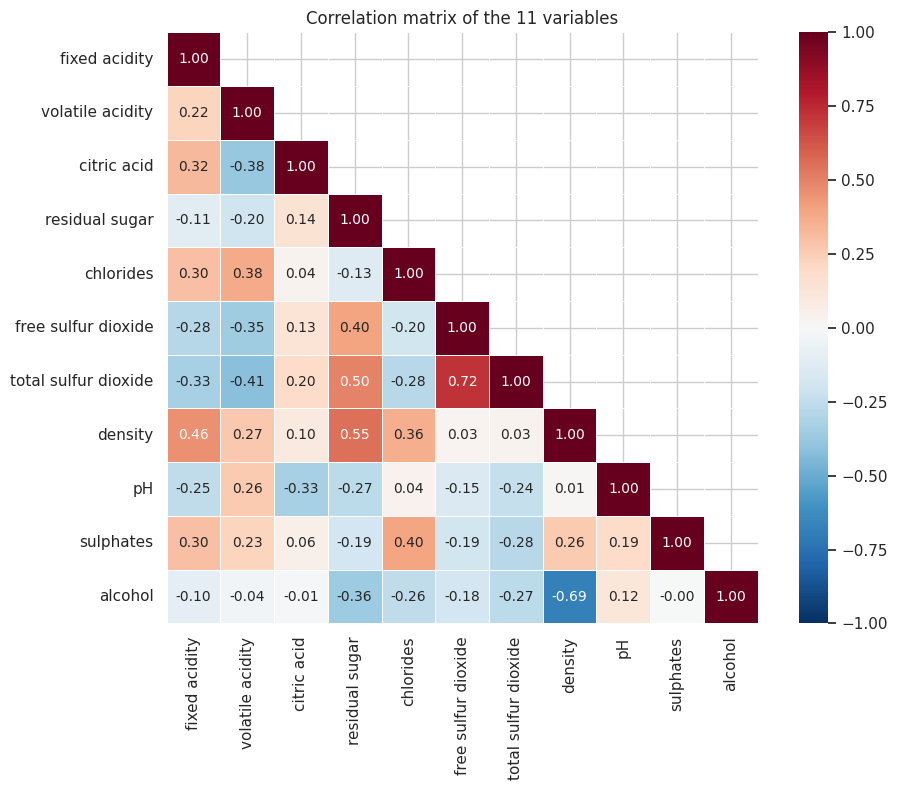

Pairs with |r| >= .30: 16 of 55
Pairs with |r| >= .50: 3 of 55


In [28]:
wine = df.copy()

# the 11 variables used in the PCA (color and quality are NOT included)
vars11 = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
          'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

X = wine[vars11]
n, p = X.shape
print('Observations:', n, '| Variables:', p, '| Cases per variable:', round(n / p))

R = X.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(R, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(R, dtype=bool), k=1), linewidths=.5)
plt.title('Correlation matrix of the 11 variables')
plt.tight_layout()
plt.show()

# how many pairs are noticeably correlated?
upper = R.values[np.triu_indices(p, k=1)]
print('Pairs with |r| >= .30:', (np.abs(upper) >= .30).sum(), 'of', len(upper))
print('Pairs with |r| >= .50:', (np.abs(upper) >= .50).sum(), 'of', len(upper))

### 1.2 Bartlett's test of sphericity

Tests whether the correlation matrix is an identity matrix (i.e., no relationships at all). We want to **reject** it.

In [29]:
det_R = np.linalg.det(R)
chi2_bartlett = -(n - 1 - (2 * p + 5) / 6) * np.log(det_R)
df_bartlett = p * (p - 1) / 2
p_bartlett = 1 - stats.chi2.cdf(chi2_bartlett, df_bartlett)

print("Determinant of R:", round(det_R, 5))
print(f"Bartlett's test: chi-square = {chi2_bartlett:.1f}, df = {df_bartlett:.0f}, p = {p_bartlett:.4g}")

Determinant of R: 0.0033
Bartlett's test: chi-square = 37094.6, df = 55, p = 0


### 1.3 Kaiser-Meyer-Olkin (KMO) measure
Compares the ordinary correlations with the *partial* correlations. Values above .60 are acceptable, above .80 are good.

In [30]:
inv_R = np.linalg.inv(R.values)
partial = -inv_R / np.sqrt(np.outer(np.diag(inv_R), np.diag(inv_R)))   # partial correlations
np.fill_diagonal(partial, 0)

r2 = R.values ** 2
np.fill_diagonal(r2, 0)
p2 = partial ** 2

kmo_each = r2.sum(axis=0) / (r2.sum(axis=0) + p2.sum(axis=0))      # one value per variable
kmo_all = r2.sum() / (r2.sum() + p2.sum())                          # overall KMO

print('Overall KMO =', round(kmo_all, 3))
pd.Series(kmo_each, index=vars11, name='KMO (per variable)').round(3).to_frame()

Overall KMO = 0.405


,KMO (per variable)
fixed acidity,0.277
volatile acidity,0.613
citric acid,0.622
residual sugar,0.294
chlorides,0.729
free sulfur dioxide,0.751
total sulfur dioxide,0.718
density,0.305
pH,0.209
sulphates,0.564


In [31]:
# Why is the overall KMO low? Check how well density can be predicted from the other 10 variables
r2_density = 1 - 1 / inv_R[vars11.index('density'), vars11.index('density')]
print('R-squared of density regressed on the other 10 variables =', round(r2_density, 3))

# KMO again, leaving density out (diagnostic only, density stays in the PCA)
vars10 = [v for v in vars11 if v != 'density']
R10 = X[vars10].corr().values
inv10 = np.linalg.inv(R10)
part10 = -inv10 / np.sqrt(np.outer(np.diag(inv10), np.diag(inv10)))
np.fill_diagonal(part10, 0)
r2_10 = R10 ** 2
np.fill_diagonal(r2_10, 0)
print('Overall KMO without density =', round(r2_10.sum() / (r2_10.sum() + (part10 ** 2).sum()), 3))

R-squared of density regressed on the other 10 variables = 0.937
Overall KMO without density = 0.663


**Conclusion (Step 1).**
- *Bartlett's test* is highly significant (p < .001): the variables are clearly correlated, so there is structure to summarize.
- *The overall KMO is low* (below .50, which is normally "unacceptable"). The reason is **density**: 94% of its variance can be predicted from the other variables (mostly alcohol, residual sugar and fixed acidity),
  so the *partial* correlations among those variables stay large, and that is what pulls KMO down. Without density, the KMO rises to about .66 (mediocre-to-middling, acceptable).
- *Decision:* the brief fixes the 11 variables, and PCA is a descriptive data-reduction method that does not strictly need a high KMO (KMO matters more for factor analysis, Part D).
  I therefore keep all 11 variables, but I treat the density–alcohol–sugar overlap as a feature of the results: it will form one component by itself.

## Step 2. Standardize the variables

The variables are on very different scales (density ≈ 0.99 g/cm³ with SD ≈ 0.003, while total sulfur dioxide ≈ 115 mg/dm³ with SD ≈ 57).
PCA finds directions of maximum **variance**. Without scaling, total and free sulfur dioxide would take up almost all the variance, and PC1 would simply be "sulfur dioxide",
only because of its units. Z-scores (mean 0, SD 1) give every variable the same variance of 1, so each variable has an equal chance to shape the components.
Running PCA on Z-scores is **exactly the same as running PCA on the correlation matrix**.

In [32]:
# Variances before standardization
print('Variance of each variable BEFORE standardization:')
print(X.var().apply(lambda v: f'{v:.6g}').to_string())

Z = (X - X.mean()) / X.std()          # z-score standardization

print('\nAfter standardization: mean ≈ 0, variance = 1')
print(pd.DataFrame({'mean': Z.mean().round(10), 'variance': Z.var().round(3)}).T.to_string())

Variance of each variable BEFORE standardization:
fixed acidity               1.68074
volatile acidity          0.0271052
citric acid               0.0211173
residual sugar              22.6367
chlorides                0.00122735
free sulfur dioxide         315.041
total sulfur dioxide        3194.72
density                 8.99204e-06
pH                        0.0258525
sulphates                 0.0221432
alcohol                     1.42256

After standardization: mean ≈ 0, variance = 1
          fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  free sulfur dioxide  total sulfur dioxide  density   pH  sulphates  alcohol
mean               -0.0               0.0          0.0             0.0        0.0                 -0.0                  -0.0     -0.0  0.0       -0.0      0.0
variance            1.0               1.0          1.0             1.0        1.0                  1.0                   1.0      1.0  1.0        1.0      1.0


In [33]:
# Demonstration: what would PCA do WITHOUT scaling?
raw_pca = PCA().fit(X)
print('Unscaled PCA – variance explained by PC1:', round(raw_pca.explained_variance_ratio_[0] * 100, 1), '%')
print('Variables with the largest weights on unscaled PC1:')
print(pd.Series(raw_pca.components_[0], index=vars11).round(3).sort_values(key=abs, ascending=False).head(3).to_string())

Unscaled PCA – variance explained by PC1: 95.4 %
Variables with the largest weights on unscaled PC1:
total sulfur dioxide    0.972
free sulfur dioxide     0.230
residual sugar          0.041


## Step 3. How many components to keep?

In [34]:
pca = PCA().fit(Z)                    # PCA on the z-scores

eigenvalues = pca.explained_variance_
prop_var = pca.explained_variance_ratio_
cum_var = np.cumsum(prop_var)
pc_names = [f'PC{i}' for i in range(1, p + 1)]

variance_table = pd.DataFrame({'Eigenvalue': eigenvalues,
                               'Proportion of variance': prop_var,
                               'Cumulative proportion': cum_var}, index=pc_names)
variance_table.round(3)

,Eigenvalue,Proportion of variance,Cumulative proportion
PC1,3.030,0.275,0.275
PC2,2.494,0.227,0.502
PC3,1.556,0.141,0.644
PC4,0.971,0.088,0.732
PC5,0.720,0.065,0.797
PC6,0.607,0.055,0.853
PC7,0.523,0.048,0.900
PC8,0.502,0.046,0.946
PC9,0.337,0.031,0.976
PC10,0.228,0.021,0.997


### 3.1 Parallel analysis

Parallel analysis creates many random datasets with the same size (6,497 × 11) and no real structure. A component is kept only if its eigenvalue is
**larger than the 95th percentile of the eigenvalues from random data**. I run it two ways:
(a) normal random data and (b) shuffling each real column independently, which keeps the real (skewed) distribution of each variable and is therefore fairer for this dataset.

In [35]:
rng = np.random.default_rng(42)
n_sims = 500

random_normal = np.zeros((n_sims, p))
random_shuffle = np.zeros((n_sims, p))

for i in range(n_sims):
    # (a) random normal data
    fake = rng.standard_normal((n, p))
    random_normal[i] = np.sort(np.linalg.eigvalsh(np.corrcoef(fake, rowvar=False)))[::-1]
    # (b) shuffle every column separately (destroys correlations, keeps distributions)
    shuffled = np.column_stack([rng.permutation(Z.values[:, j]) for j in range(p)])
    random_shuffle[i] = np.sort(np.linalg.eigvalsh(np.corrcoef(shuffled, rowvar=False)))[::-1]

pa_normal = np.percentile(random_normal, 95, axis=0)
pa_shuffle = np.percentile(random_shuffle, 95, axis=0)

compare = pd.DataFrame({'Eigenvalue': eigenvalues,
                        'Parallel (normal) 95th': pa_normal,
                        'Parallel (shuffled) 95th': pa_shuffle}, index=pc_names)
compare['Kaiser (>1)'] = compare['Eigenvalue'] > 1
compare['Beats parallel (normal)'] = compare['Eigenvalue'] > compare['Parallel (normal) 95th']
compare['Beats parallel (shuffled)'] = compare['Eigenvalue'] > compare['Parallel (shuffled) 95th']
compare.round(3)

,Eigenvalue,Parallel (normal) 95th,Parallel (shuffled) 95th,Kaiser (>1),Beats parallel (normal),Beats parallel (shuffled)
PC1,3.030,1.084,1.082,True,True,True
PC2,2.494,1.060,1.059,True,True,True
PC3,1.556,1.044,1.043,True,True,True
PC4,0.971,1.031,1.031,False,False,False
PC5,0.720,1.019,1.020,False,False,False
PC6,0.607,1.008,1.008,False,False,False
PC7,0.523,0.996,0.997,False,False,False
PC8,0.502,0.986,0.986,False,False,False
PC9,0.337,0.975,0.975,False,False,False
PC10,0.228,0.964,0.962,False,False,False


### 3.2 Scree plot with benchmarks

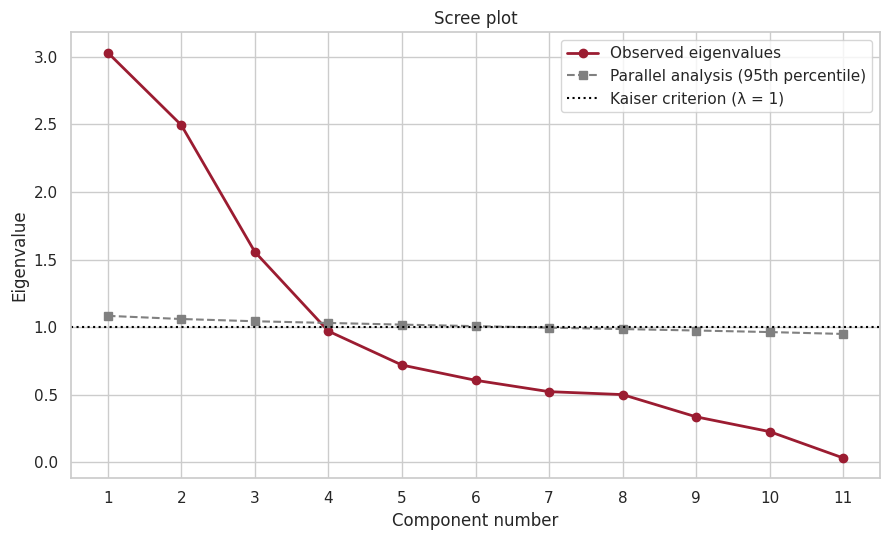

In [36]:
x = np.arange(1, p + 1)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(x, eigenvalues, 'o-', color='#9b1c31', lw=2, label='Observed eigenvalues')
ax.plot(x, pa_normal, 's--', color='gray', label='Parallel analysis (95th percentile)')
ax.axhline(1, color='black', ls=':', label='Kaiser criterion (λ = 1)')
ax.set_xticks(x); ax.set_xlabel('Component number'); ax.set_ylabel('Eigenvalue')
ax.set_title('Scree plot')
ax.legend()
plt.tight_layout()
plt.show()

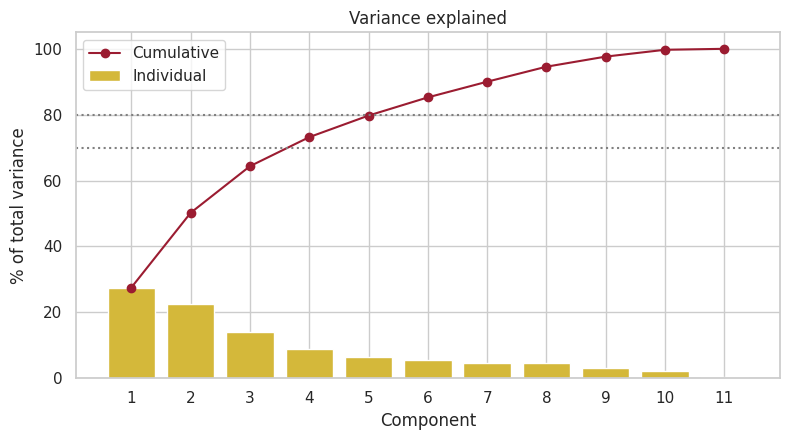

In [37]:
# Cumulative variance plot
plt.figure(figsize=(8, 4.5))
plt.bar(x, prop_var * 100, color='#d4b83a', label='Individual')
plt.plot(x, cum_var * 100, 'o-', color='#9b1c31', label='Cumulative')
plt.axhline(70, color='gray', ls=':'); plt.axhline(80, color='gray', ls=':')
plt.xticks(x); plt.xlabel('Component'); plt.ylabel('% of total variance'); plt.legend()
plt.title('Variance explained')
plt.tight_layout()
plt.show()

### 3.3 Decision
The table and plots above are compared across the criteria: Kaiser rule, the elbow of the scree plot, cumulative variance (rules of thumb of 70–80%) and parallel analysis.
The final choice and justification are in the interpretation at the end of this notebook.

In [38]:
# Number of components to keep (see the interpretation at the end for the reasoning)
k = 3                                  # decision: keep 3 components (Kaiser, parallel analysis and scree all agree)
print('Components kept:', k)
print('Components with eigenvalue > 1:', int((eigenvalues > 1).sum()))
print('Components that beat parallel analysis (shuffled):', int(compare['Beats parallel (shuffled)'].sum()))

Components kept: 3
Components with eigenvalue > 1: 3
Components that beat parallel analysis (shuffled): 3


## Step 4. PCA results
### 4.1 Eigenvalues and variance explained

In [39]:
variance_table.round(3)

,Eigenvalue,Proportion of variance,Cumulative proportion
PC1,3.030,0.275,0.275
PC2,2.494,0.227,0.502
PC3,1.556,0.141,0.644
PC4,0.971,0.088,0.732
PC5,0.720,0.065,0.797
PC6,0.607,0.055,0.853
PC7,0.523,0.048,0.900
PC8,0.502,0.046,0.946
PC9,0.337,0.031,0.976
PC10,0.228,0.021,0.997


### 4.2 Component loadings (unrotated)
A loading is the correlation between a variable and a component (eigenvector × √eigenvalue). Communality = the share of a variable's variance captured by the kept components.

In [40]:
loadings_all = pd.DataFrame(pca.components_.T * np.sqrt(eigenvalues), index=vars11, columns=pc_names)

loadings = loadings_all.iloc[:, :k].copy()
loadings['Communality'] = (loadings ** 2).sum(axis=1)
loadings['Uniqueness'] = 1 - loadings['Communality']
loadings.round(3)

,PC1,PC2,PC3,Communality,Uniqueness
fixed acidity,-0.416,0.531,0.542,0.748,0.252
volatile acidity,-0.663,0.186,-0.383,0.621,0.379
citric acid,0.265,0.289,0.737,0.697,0.303
residual sugar,0.602,0.521,-0.205,0.676,0.324
chlorides,-0.505,0.498,-0.021,0.503,0.497
free sulfur dioxide,0.750,0.114,-0.167,0.604,0.396
total sulfur dioxide,0.848,0.138,-0.134,0.757,0.243
density,-0.078,0.922,-0.219,0.905,0.095
pH,-0.381,-0.246,-0.568,0.528,0.472
sulphates,-0.512,0.303,0.087,0.361,0.639


In [41]:
# Same table with the large loadings (|loading| >= .40) highlighted
def highlight(v):
    return 'background-color: #ffe08a; font-weight: bold' if abs(v) >= 0.40 else ''

loadings.iloc[:, :k].round(3).style.map(highlight)

,PC1,PC2,PC3
fixed acidity,-0.416000,0.531000,0.542000
volatile acidity,-0.663000,0.186000,-0.383000
citric acid,0.265000,0.289000,0.737000
residual sugar,0.602000,0.521000,-0.205000
chlorides,-0.505000,0.498000,-0.021000
free sulfur dioxide,0.750000,0.114000,-0.167000
total sulfur dioxide,0.848000,0.138000,-0.134000
density,-0.078000,0.922000,-0.219000
pH,-0.381000,-0.246000,-0.568000
sulphates,-0.512000,0.303000,0.087000


### 4.3 Rotated loadings (varimax)
Rotation does not change how much variance the components explain together. It only redistributes the variance so that each variable loads strongly on one component, which makes the components easier to name.

In [42]:
def varimax(L, max_iter=100, tol=1e-6):
    # Standard varimax rotation of a loading matrix L (variables x components)
    p_, k_ = L.shape
    R_ = np.eye(k_)
    d = 0
    for _ in range(max_iter):
        Lr = L @ R_
        u, s, vt = np.linalg.svd(L.T @ (Lr ** 3 - Lr @ np.diag((Lr ** 2).sum(axis=0)) / p_))
        R_ = u @ vt
        d_new = s.sum()
        if d_new < d * (1 + tol):
            break
        d = d_new
    return L @ R_

rot = varimax(loadings_all.iloc[:, :k].values)
rotated = pd.DataFrame(rot, index=vars11, columns=[f'RC{i}' for i in range(1, k + 1)])

# order the rotated components by the variance they carry
ss = (rotated ** 2).sum()
rotated = rotated[ss.sort_values(ascending=False).index]
rotated.columns = [f'RC{i}' for i in range(1, k + 1)]
ss_sorted = (rotated ** 2).sum()

print('Variance explained by each rotated component (%):')
print((ss_sorted / p * 100).round(1).to_string())
print('Total (same as unrotated):', round(ss_sorted.sum() / p * 100, 1), '%')
rotated.round(3).style.map(highlight)

Variance explained by each rotated component (%):
RC1    26.8
RC2    21.9
RC3    15.7
Total (same as unrotated): 64.4 %


,RC1,RC2,RC3
fixed acidity,-0.539000,0.360000,0.573000
volatile acidity,-0.556000,0.336000,-0.445000
citric acid,0.080000,0.028000,0.831000
residual sugar,0.626000,0.521000,0.114000
chlorides,-0.493000,0.509000,0.024000
free sulfur dioxide,0.767000,0.114000,0.053000
total sulfur dioxide,0.854000,0.120000,0.114000
density,-0.038000,0.948000,0.074000
pH,-0.232000,-0.032000,-0.688000
sulphates,-0.523000,0.291000,0.060000


## Step 5. Visualizations

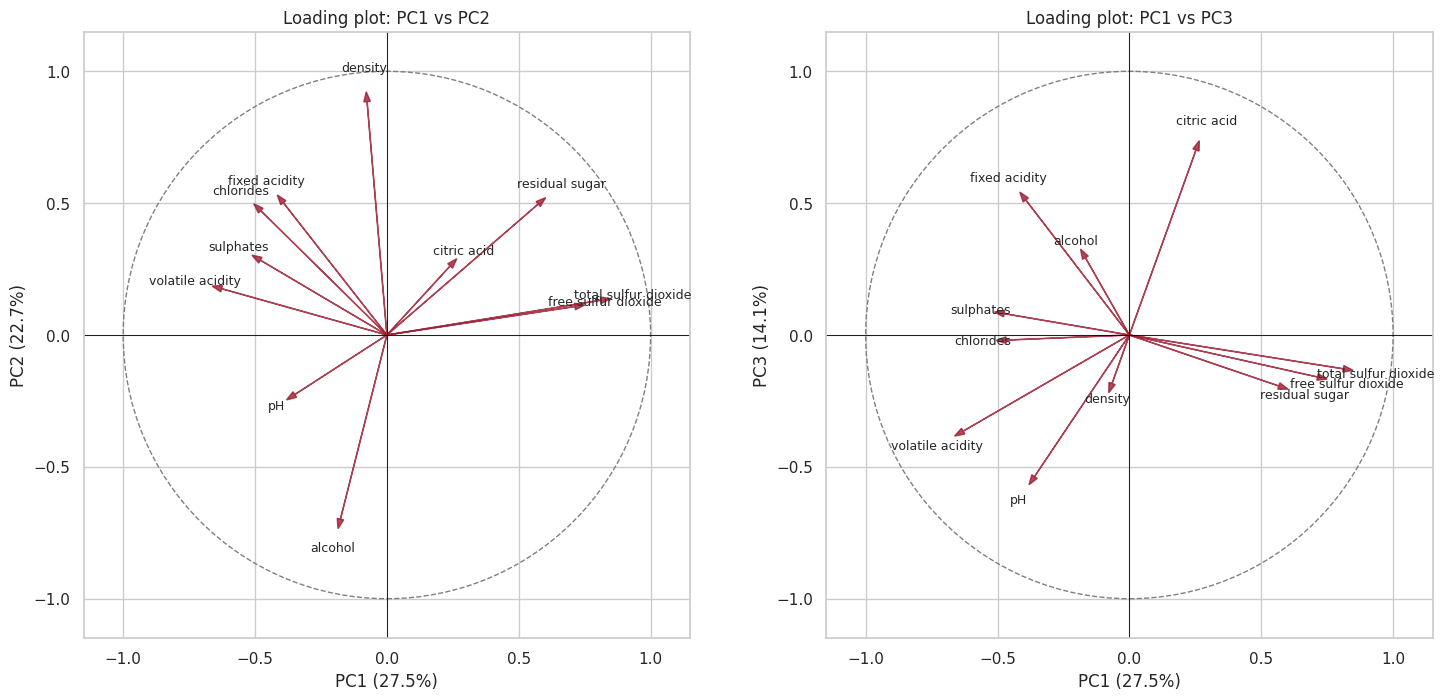

In [43]:
def loading_plot(ax, a, b):
    # a, b = indices of the two components (0 = PC1)
    circle = plt.Circle((0, 0), 1, fill=False, color='gray', ls='--')
    ax.add_patch(circle)
    for v in vars11:
        ax.arrow(0, 0, loadings_all.loc[v, pc_names[a]], loadings_all.loc[v, pc_names[b]],
                 head_width=0.025, color='#9b1c31', alpha=.8, length_includes_head=True)
        ax.text(loadings_all.loc[v, pc_names[a]] * 1.10, loadings_all.loc[v, pc_names[b]] * 1.10,
                v, fontsize=9, ha='center', va='center')
    ax.axhline(0, color='black', lw=.6); ax.axvline(0, color='black', lw=.6)
    ax.set_xlim(-1.15, 1.15); ax.set_ylim(-1.15, 1.15); ax.set_aspect('equal')
    ax.set_xlabel(f'{pc_names[a]} ({prop_var[a]*100:.1f}%)')
    ax.set_ylabel(f'{pc_names[b]} ({prop_var[b]*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
loading_plot(axes[0], 0, 1); axes[0].set_title('Loading plot: PC1 vs PC2')
loading_plot(axes[1], 0, 2); axes[1].set_title('Loading plot: PC1 vs PC3')
plt.tight_layout()
plt.show()

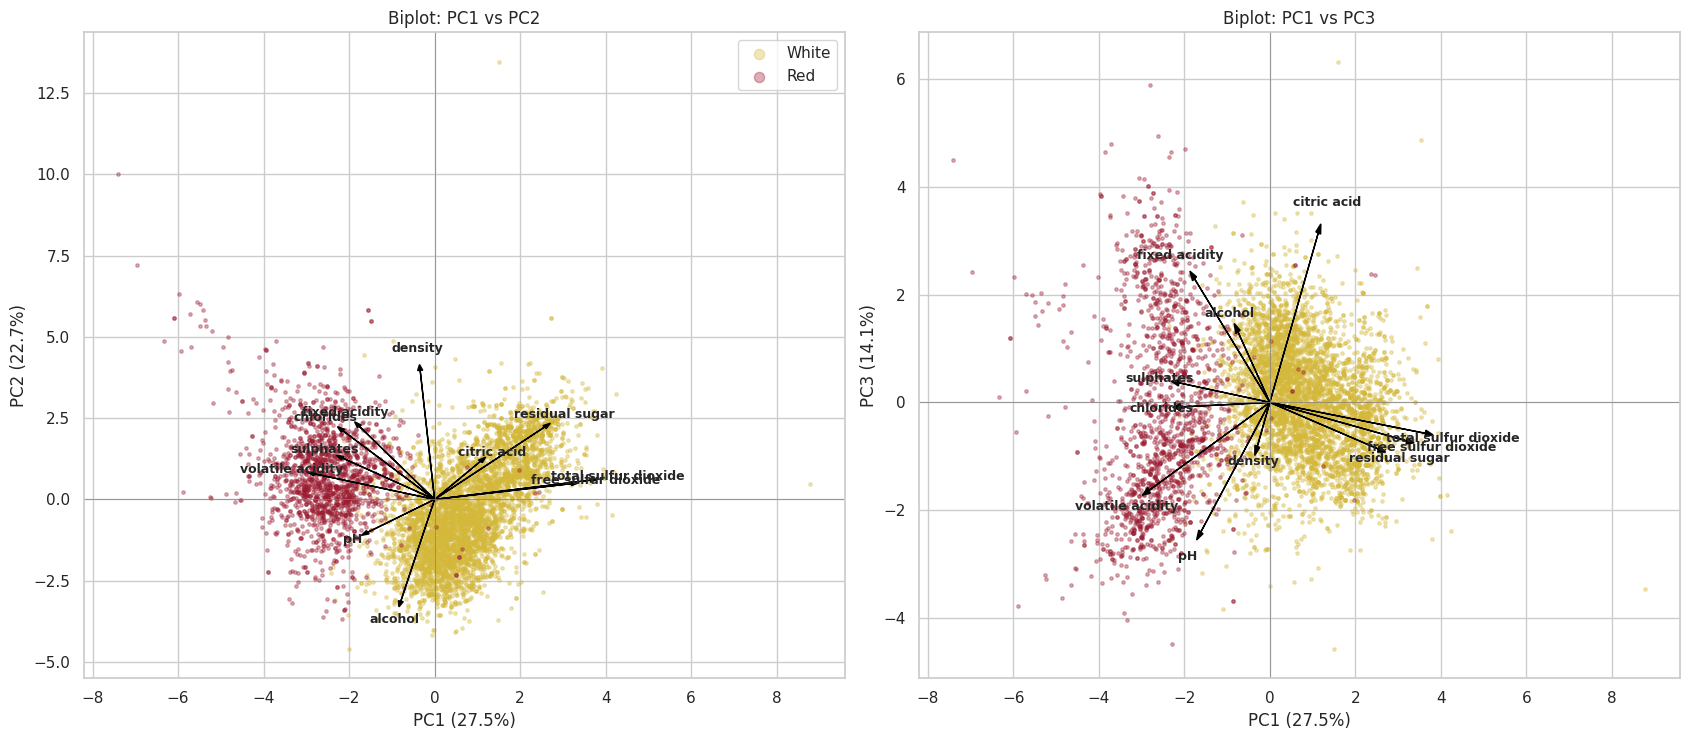

In [44]:
scores = pd.DataFrame(pca.transform(Z), columns=pc_names)
scores['color'] = wine['color'].values

def biplot(ax, a, b):
    for c in ['White', 'Red']:
        s = scores[scores['color'] == c]
        ax.scatter(s[pc_names[a]], s[pc_names[b]], s=6, alpha=.35, color=colors[c], label=c)
    scale = 4.5                                   # stretch the arrows so they are visible next to the points
    for v in vars11:
        ax.arrow(0, 0, loadings_all.loc[v, pc_names[a]] * scale, loadings_all.loc[v, pc_names[b]] * scale,
                 head_width=0.12, color='black', length_includes_head=True)
        ax.text(loadings_all.loc[v, pc_names[a]] * scale * 1.12, loadings_all.loc[v, pc_names[b]] * scale * 1.12,
                v, fontsize=9, ha='center', va='center', weight='bold')
    ax.axhline(0, color='gray', lw=.5); ax.axvline(0, color='gray', lw=.5)
    ax.set_xlabel(f'{pc_names[a]} ({prop_var[a]*100:.1f}%)'); ax.set_ylabel(f'{pc_names[b]} ({prop_var[b]*100:.1f}%)')

fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
biplot(axes[0], 0, 1); axes[0].set_title('Biplot: PC1 vs PC2'); axes[0].legend(markerscale=3)
biplot(axes[1], 0, 2); axes[1].set_title('Biplot: PC1 vs PC3')
plt.tight_layout()
plt.show()

PC1         PC2         PC3      
       mean   std  mean   std  mean   std
color                                    
Red   -2.51  0.89  0.78  1.43 -0.18  1.77
White  0.82  1.01 -0.25  1.54  0.06  1.02

PC1: Cohen's d (Red - White) = -3.39
PC2: Cohen's d (Red - White) = 0.68
PC3: Cohen's d (Red - White) = -0.20


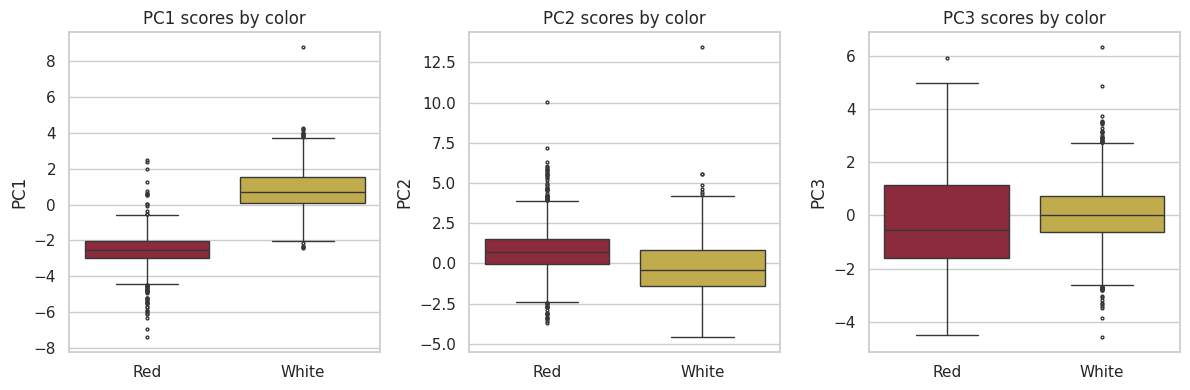

In [45]:
score_means = scores.groupby('color')[pc_names[:k]].agg(['mean', 'std']).round(2)
display(score_means)

# effect size (Cohen's d) of red vs white on each retained component
red_s, white_s = scores[scores.color == 'Red'], scores[scores.color == 'White']
for pc in pc_names[:k]:
    sd_pool = np.sqrt(((len(red_s)-1)*red_s[pc].var() + (len(white_s)-1)*white_s[pc].var()) / (len(scores)-2))
    print(f"{pc}: Cohen's d (Red - White) = {(red_s[pc].mean() - white_s[pc].mean()) / sd_pool:.2f}")

fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
for ax, pc in zip(np.atleast_1d(axes), pc_names[:k]):
    sns.boxplot(data=scores, x='color', y=pc, hue='color', palette=colors, ax=ax, fliersize=2, legend=False)
    ax.set_title(f'{pc} scores by color'); ax.set_xlabel('')
plt.tight_layout()
plt.show()

## Step 6. Robustness checks
(a) PCA on log-transformed skewed variables (outliers and skew can pull components), and
(b) PCA after removing the red/white mean difference (to see the within-color structure).

In [46]:
skewed = ['residual sugar', 'chlorides', 'sulphates', 'free sulfur dioxide', 'volatile acidity']

# (a) log-transform the skewed variables, then standardize
X_log = X.copy()
X_log[skewed] = np.log(X_log[skewed])
Z_log = (X_log - X_log.mean()) / X_log.std()
pca_log = PCA().fit(Z_log)

# (b) subtract each color's own mean, then standardize
X_within = X - X.groupby(wine['color']).transform('mean')
Z_within = X_within / X_within.std()
pca_within = PCA().fit(Z_within)

robust = pd.DataFrame({
    'Original': pca.explained_variance_ratio_[:5] * 100,
    'Log-transformed': pca_log.explained_variance_ratio_[:5] * 100,
    'Within-color': pca_within.explained_variance_ratio_[:5] * 100}, index=pc_names[:5]).round(1)
print('% variance explained by the first 5 components:'); display(robust)

print('Eigenvalues > 1:  original =', (pca.explained_variance_ > 1).sum(),
      '| log =', (pca_log.explained_variance_ > 1).sum(),
      '| within-color =', (pca_within.explained_variance_ > 1).sum())

# do the loadings look the same? (correlation between PC1-PC3 loadings of original vs log PCA; sign-free)
for i in range(3):
    r_log = np.corrcoef(pca.components_[i], pca_log.components_[i])[0, 1]
    print(f'PC{i+1}: loading similarity original vs log (|r|) = {abs(r_log):.2f}')

% variance explained by the first 5 components:


,Original,Log-transformed,Within-color
PC1,27.5,28.4,28.0
PC2,22.7,22.9,17.5
PC3,14.1,14.0,11.7
PC4,8.8,8.7,10.1
PC5,6.5,6.4,8.3


Eigenvalues > 1:  original = 3 | log = 3 | within-color = 4
PC1: loading similarity original vs log (|r|) = 0.97
PC2: loading similarity original vs log (|r|) = 0.95
PC3: loading similarity original vs log (|r|) = 0.99


In [47]:
# loadings from the within-color PCA (first 3 components)
within_load = pd.DataFrame(pca_within.components_.T * np.sqrt(pca_within.explained_variance_),
                           index=vars11, columns=pc_names)
within_load.iloc[:, :4].round(2).style.map(highlight)

,PC1,PC2,PC3,PC4
fixed acidity,0.370000,0.730000,-0.200000,-0.100000
volatile acidity,-0.050000,-0.460000,-0.480000,0.350000
citric acid,0.340000,0.690000,0.260000,-0.100000
residual sugar,0.740000,-0.200000,-0.220000,-0.190000
chlorides,0.340000,0.110000,0.060000,0.770000
free sulfur dioxide,0.500000,-0.340000,0.490000,-0.280000
total sulfur dioxide,0.670000,-0.350000,0.320000,-0.110000
density,0.900000,-0.090000,-0.200000,0.000000
pH,-0.330000,-0.570000,0.350000,0.040000
sulphates,0.140000,0.200000,0.590000,0.470000


## Summary of results and interpretation

### Is PCA justified? (Step 1)
Bartlett's test is significant (χ²(55) = 37,094.6, p < .001), and 16 of 55 pairs of variables have |r| ≥ .30, so there is real shared structure.
The overall **KMO is .405**, which is below the usual .50 minimum. This comes from **density**, which is almost entirely predictable from the other variables (R² = .94). Without it the KMO is about .66.
Because the brief fixes the 11 variables and PCA is descriptive, I proceed, but the low KMO is a limitation to mention: it means that part of the correlation structure is a near-linear dependency (density ≈ alcohol + sugar), not several independent relationships.

### Why standardize? (Step 2)
Raw variances range from 0.000009 (density) to 3,195 (total sulfur dioxide). Without scaling, PC1 would explain **95.4%** of the variance and would be almost entirely total sulfur dioxide (weight .97),
simply because of its units. Z-scoring (equivalently, using the correlation matrix) gives every variable a variance of 1, so the components reflect the *relationships* among variables, not their measurement units.

### How many components? (Step 3)
| Criterion | Result |
|---|---|
| Kaiser (λ > 1) | 3 components (λ = 3.03, 2.49, 1.56). The 4th is just below the cutoff (λ = 0.97). |
| Parallel analysis (95th percentile, both versions) | 3 components. The 4th (0.97) is below the random-data benchmark of 1.03. |
| Scree plot | Clear drop after PC3, with the curve flattening from PC4 onward. |
| Cumulative variance | 3 PCs = **64.4%**; 4 PCs = 73.2%; 5 PCs = 79.7%. |

Three of the criteria agree on **3 components**. The variance rule of thumb (70–80%) would ask for 4–5, but the 4th component is not distinguishable from noise by parallel analysis and has an eigenvalue below 1, so it is not worth keeping.
The cost is that **35.6% of the variance is not captured**. That is a modest reduction (11 variables → 3), not a very efficient one, which fits the weak overall correlation structure (only 3 pairs with |r| ≥ .50).

### The retained components (Steps 4–6)
Variance explained: PC1 = 27.5%, PC2 = 22.7%, PC3 = 14.1% (total 64.4%). Loadings of |.40| or more are treated as substantial. Varimax rotation gives the same picture, with slightly cleaner loadings.

| Component | Strong positive loadings | Strong negative loadings | Name |
|---|---|---|---|
| **PC1** (27.5%) | total SO₂ (.85), free SO₂ (.75), residual sugar (.60) | volatile acidity (−.66), sulphates (−.51), chlorides (−.50), fixed acidity (−.42) | **Preservation (sulfur dioxide and sugar) vs. acidity-and-salts profile**, the red-vs-white "wine style" axis |
| **PC2** (22.7%) | density (.92), fixed acidity (.53), residual sugar (.52), chlorides (.50) | alcohol (−.73) | **Density–sweetness–alcohol balance** (body/sugar-alcohol axis) |
| **PC3** (14.1%) | citric acid (.74), fixed acidity (.54) | pH (−.57), volatile acidity (−.38, just under the cutoff) | **Fresh acidity** (citric/fixed acids vs. pH) |

- **PC1** contrasts wines rich in sulfur dioxide and sugar with wines rich in volatile acidity, chlorides and sulphates. It is essentially the **red/white axis**: red wines average −2.51 and white +0.82 on PC1 (Cohen's d = −3.39), much larger than on PC2 (d = 0.68) or PC3 (d = −0.20). This agrees with the large MANOVA effect in Part B.
- **PC2** reflects that sugar raises density while alcohol lowers it, so wines with high density tend to be sweeter and lower in alcohol. Density has the highest communality (.91), because this component is mostly "density".
- **PC3** separates wines with high citric and fixed acid and low pH (acidic, fresh-tasting) from those with high pH and more volatile acidity.

### Robustness
Log-transforming the skewed variables gives almost identical results (variance explained 28.4/22.9/14.0%; loading similarity |r| = .95–.99). After removing the red/white mean difference, the structure changes in a meaningful way:
the density–sugar–alcohol axis becomes the largest component (28.0%), an acidity axis (fixed/citric acid vs. pH) comes second (17.5%), and a **4th** component with eigenvalue 1.12 appears (chlorides and sulphates).
So the **red/white contrast is what makes PC1 the largest component in the pooled data**, and a within-color analysis might support a fourth dimension.

## Answer to the research question

**Three components are enough to summarize the 11 measurements, and together they retain 64.4% of the total variance** (27.5% + 22.7% + 14.1%). The 4th and later components fall below the parallel-analysis benchmark and add less than 9% each.
The three components represent distinct aspects of wine chemistry:
1. **Preservation vs. acidity/salts profile** (sulfur dioxide and sugar against volatile acidity, chlorides and sulphates), which largely distinguishes white from red wines.
2. **Density–sweetness–alcohol balance**, the body of the wine, in which sugar raises density and alcohol lowers it.
3. **Fresh acidity**, the citric/fixed-acid content against pH.

**Limitations.** A third of the variance is lost, so the reduction is moderate. The overall KMO (.405) is low because of density. The pooled solution partly reflects the red/white split, and the data are skewed (although the log check suggests the conclusions are stable).

---

# 7. Part D – Exploratory Factor Analysis (EFA) [20 points]

Conduct an Exploratory Factor Analysis (EFA) using the 11 physicochemical variables. The purpose is to investigate whether the observed chemical measurements can be explained by a smaller number of underlying latent factors.

### Variables for EFA
Use the following **11 physicochemical variables**:
* `fixed acidity`
* `volatile acidity`
* `citric acid`
* `residual sugar`
* `chlorides`
* `free sulfur dioxide`
* `total sulfur dioxide`
* `density`
* `pH`
* `sulphates`
* `alcohol`

## Required Tasks

### 1. Assess Factorability
Report and interpret statistical diagnostics to evaluate whether the dataset is suitable for factor analysis:
* **Correlation Matrix:** Inspect pairwise relationships among variables.
* **Kaiser-Meyer-Olkin (KMO) Measure of Sampling Adequacy:** Report overall KMO and individual MSA values.
* **Bartlett’s Test of Sphericity:** Report test statistic ($\chi^2$), degrees of freedom ($df$), and $p$-value.
* **Conclusion:** Explain explicitly whether the data matrix is factorable.

### 2. Determine the Number of Factors
Use multiple criteria to decide on the optimal number of latent factors to retain:
* **Scree Plot** (elbow criterion)
* **Parallel Analysis** (simulated vs. empirical eigenvalues)
* **Eigenvalues** ($\lambda > 1$ criterion)
* **Theoretical Interpretability** in wine chemistry

Provide a formal justification for your decision.

### 3. Select an Extraction Method
Choose an appropriate factor extraction method (e.g., Principal Axis Factoring (PAF), Maximum Likelihood (ML), or Minimum Residual (MinRes)):
* State your selected extraction method.
* Explain why it is appropriate for your data structure and distribution.


### 4. Select a Rotation Method
Apply an appropriate factor rotation method:
* **Oblique Rotation** (e.g., Promax, Direct Oblimin): Use if underlying latent factors are expected to be correlated in wine chemistry.
* **Orthogonal Rotation** (e.g., Varimax): Use if factors are assumed to be strictly independent.

> **Requirement:** You must explicitly justify your choice of rotation based on expected factor correlations.

### 5. Examine Factor Loadings
Report and interpret the factor pattern/structure matrices:
* **Factor Loadings:** Report loading coefficients for each variable across retained factors.
* **Communalities ($h^2$):** Evaluate the proportion of variance in each variable explained by the factors.
* **Uniqueness ($u^2$):** Report unique/unexplained variance ($1 - h^2$).
* **Diagnostic Flags:** Identify variables that:
  * Load strongly on a single factor (e.g., $\vert{}\text{loading}\vert{} \ge 0.40$).
  * Have weak overall loadings across all factors.
  * Exhibit substantial cross-loadings across multiple factors.

### 6. Interpret the Factors
Assign each retained latent factor a meaningful descriptive name based on the specific variables that load heavily on it.

## Required Interpretation

Answer the core research question:
* **What underlying dimensions of wine physicochemical characteristics are revealed by the factor analysis?**

> **Guidance:** Your factor names must be directly supported by the observed high-loading variables and grounded in domain knowledge of wine chemistry (e.g., volatile/fixed acidity dimensions, preservation/sulfite factors, or body/density/alcohol constructs).

In [48]:
vars11 = ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
          'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

X = wine[vars11]
n, p = X.shape
Z = (X - X.mean()) / X.std()          # standardized data (EFA works on the correlation matrix)
R = X.corr().values                   # correlation matrix
print('Observations:', n, '| Variables:', p)

wine = df.copy()

Observations: 6497 | Variables: 11


## Step 0b. Helper functions (extraction and rotation)
These small functions are written in plain NumPy so the notebook does not depend on extra packages
(the `factor_analyzer` package currently fails with recent versions of scikit-learn).

In [49]:
def paf(R, k, max_iter=1000, tol=1e-8, h2_max=0.995):
    # Principal Axis Factoring: repeatedly factor the correlation matrix whose diagonal holds the
    # communalities (shared variance), until the communalities stop changing.
    h2 = 1 - 1 / np.diag(np.linalg.inv(R))               # start with squared multiple correlations
    for i in range(max_iter):
        Rr = R.copy()
        np.fill_diagonal(Rr, h2)                          # "reduced" correlation matrix
        vals, vecs = np.linalg.eigh(Rr)
        top = np.argsort(vals)[::-1][:k]                  # k largest eigenvalues
        L = vecs[:, top] * np.sqrt(np.clip(vals[top], 0, None))   # unrotated loadings
        h2_new = np.minimum((L ** 2).sum(axis=1), h2_max) # cap communalities just below 1 (Heywood cases)
        if np.max(np.abs(h2_new - h2)) < tol:
            h2 = h2_new
            break
        h2 = h2_new
    return L, h2, i + 1

def varimax(L, max_iter=500, tol=1e-8):
    # Varimax (orthogonal) rotation with Kaiser normalization
    p_, k_ = L.shape
    w = np.sqrt((L ** 2).sum(axis=1, keepdims=True))
    A = L / w
    T = np.eye(k_)
    d = 0
    for _ in range(max_iter):
        B = A @ T
        u, s, vt = np.linalg.svd(A.T @ (B ** 3 - B @ np.diag((B ** 2).sum(axis=0)) / p_))
        T = u @ vt
        if s.sum() < d * (1 + tol):
            break
        d = s.sum()
    return (A @ T) * w

def promax(L, power=4):
    # Promax (oblique) rotation: start from varimax, then let the factors correlate.
    # Returns the pattern matrix and the factor correlation matrix (phi).
    Lv = varimax(L)
    target = Lv * np.abs(Lv) ** (power - 1)
    U = np.linalg.lstsq(Lv, target, rcond=None)[0]
    U = U @ np.diag(np.sqrt(np.diag(np.linalg.inv(U.T @ U))))
    return Lv @ U, np.linalg.inv(U.T @ U)

def tidy(P, phi, h2):
    # order factors by the variance they carry and flip signs so the largest loading is positive
    order = np.argsort(-(P ** 2).sum(axis=0))
    P, phi = P[:, order], phi[np.ix_(order, order)]
    sign = np.sign(P[np.abs(P).argmax(axis=0), range(P.shape[1])])
    return P * sign, phi * np.outer(sign, sign)

## Step 1. Is the data factorable?
### 1.1 Correlation matrix

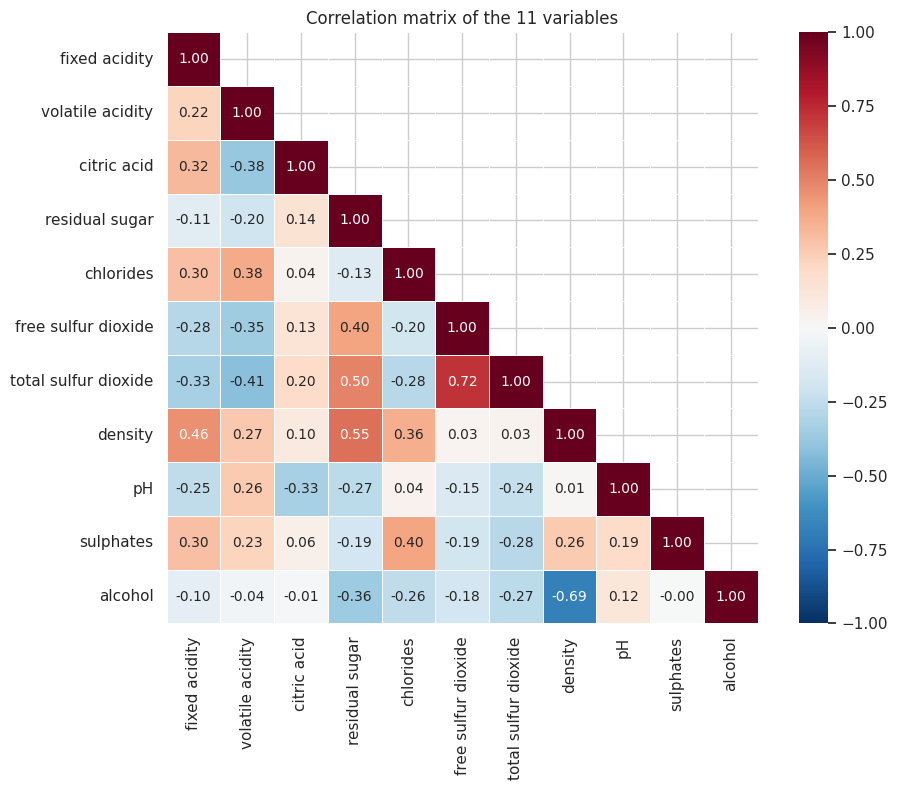

Pairs with |r| >= .30: 16 of 55
Pairs with |r| >= .50: 3 of 55
Determinant of R: 0.0033


In [50]:
corr = pd.DataFrame(R, index=vars11, columns=vars11)
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, square=True,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), linewidths=.5)
plt.title('Correlation matrix of the 11 variables')
plt.tight_layout()
plt.show()

upper = R[np.triu_indices(p, k=1)]
print('Pairs with |r| >= .30:', (np.abs(upper) >= .30).sum(), 'of', len(upper))
print('Pairs with |r| >= .50:', (np.abs(upper) >= .50).sum(), 'of', len(upper))
print('Determinant of R:', round(np.linalg.det(R), 4))

## Step 2. How many factors?

In [51]:
# Eigenvalues of the correlation matrix (Kaiser) and of the reduced matrix (communalities on the diagonal)
eig_R = np.sort(np.linalg.eigvalsh(R))[::-1]

def reduced_eigs(Rm):
    h = 1 - 1 / np.diag(np.linalg.inv(Rm))
    Rr = Rm.copy(); np.fill_diagonal(Rr, h)
    return np.sort(np.linalg.eigvalsh(Rr))[::-1]

eig_reduced = reduced_eigs(R)

# Parallel analysis: eigenvalues from random data of the same size (95th percentile)
rng = np.random.default_rng(42)
sims = 500
rand_full = np.zeros((sims, p))
rand_reduced = np.zeros((sims, p))
for i in range(sims):
    fake = rng.standard_normal((n, p))
    Rf = np.corrcoef(fake, rowvar=False)
    rand_full[i] = np.sort(np.linalg.eigvalsh(Rf))[::-1]
    rand_reduced[i] = reduced_eigs(Rf)

pa_full = np.percentile(rand_full, 95, axis=0)
pa_reduced = np.percentile(rand_reduced, 95, axis=0)

table = pd.DataFrame({'Eigenvalue (R)': eig_R, 'Parallel 95th (R)': pa_full,
                      'Eigenvalue (reduced R)': eig_reduced, 'Parallel 95th (reduced)': pa_reduced},
                     index=[f'F{i}' for i in range(1, p + 1)])
table['Kaiser > 1'] = table['Eigenvalue (R)'] > 1
table['Beats parallel (R)'] = table['Eigenvalue (R)'] > table['Parallel 95th (R)']
table['Beats parallel (reduced)'] = table['Eigenvalue (reduced R)'] > table['Parallel 95th (reduced)']
table.round(2)

,Eigenvalue (R),Parallel 95th (R),Eigenvalue (reduced R),Parallel 95th (reduced),Kaiser > 1,Beats parallel (R),Beats parallel (reduced)
F1,3.03,1.08,2.63,0.08,True,True,True
F2,2.49,1.06,2.28,0.06,True,True,True
F3,1.56,1.04,1.15,0.05,True,True,True
F4,0.97,1.03,0.47,0.03,False,False,True
F5,0.72,1.02,0.40,0.02,False,False,True
F6,0.61,1.01,0.20,0.01,False,False,True
F7,0.52,1.00,0.16,-0.00,False,False,True
F8,0.50,0.99,-0.07,-0.01,False,False,False
F9,0.34,0.97,-0.11,-0.03,False,False,False
F10,0.23,0.96,-0.13,-0.04,False,False,False


- **Kaiser (λ > 1):** 3 factors (λ = 3.03, 2.49, 1.56; the fourth is 0.97).
- **Parallel analysis on R** (the standard version): 3 factors; the fourth eigenvalue (0.97) is below the random benchmark (about 1.03).
- **Parallel analysis on the reduced matrix:** the benchmark is almost zero for random data when n = 6,497, so *any* positive eigenvalue passes and the test suggests 7 factors. With a sample this large this version is too liberal to be useful, so I show it but do not use it alone.

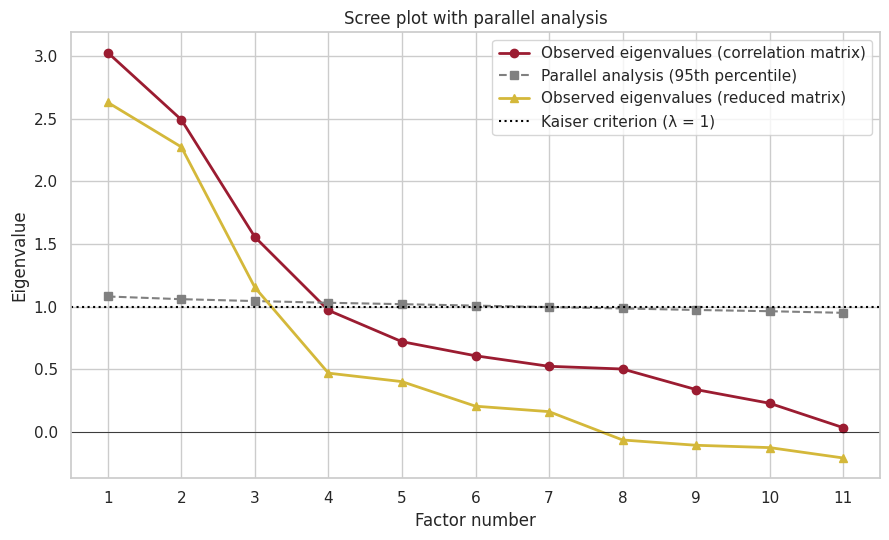

In [53]:
x = np.arange(1, p + 1)
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.plot(x, eig_R, 'o-', color='#9b1c31', lw=2, label='Observed eigenvalues (correlation matrix)')
ax.plot(x, pa_full, 's--', color='gray', label='Parallel analysis (95th percentile)')
ax.plot(x, eig_reduced, '^-', color='#d4b83a', lw=2, label='Observed eigenvalues (reduced matrix)')
ax.axhline(1, color='black', ls=':', label='Kaiser criterion (λ = 1)')
ax.axhline(0, color='black', lw=.5)
ax.set_xticks(x); ax.set_xlabel('Factor number'); ax.set_ylabel('Eigenvalue'); ax.set_title('Scree plot with parallel analysis')
ax.legend()
plt.tight_layout()
plt.show()

### 2.2 Compare candidate solutions (2 to 5 factors)
For each number of factors I extract with PAF, rotate with Promax, and record the fit (RMSR = root mean squared residual between the observed and reproduced correlations; below .05 is good, below .08 acceptable)
and whether the solution is clean (improper communalities, factors with too few salient variables).

In [54]:
rows = []
for k_try in [2, 3, 4, 5]:
    L_, h2_, _ = paf(R, k_try)
    P_, phi_ = promax(L_)
    resid = R - L_ @ L_.T
    np.fill_diagonal(resid, 0)
    salient = (np.abs(P_) >= .40).sum(axis=0)                     # variables with |loading| >= .40 on each factor
    rows.append({'Factors': k_try,
                 '% variance (extraction)': 100 * (L_ ** 2).sum() / p,
                 'RMSR': np.sqrt((resid[np.triu_indices(p, 1)] ** 2).mean()),
                 'Communalities at cap (Heywood)': int((h2_ >= .994).sum()),
                 'Salient loadings per factor': list(np.sort(salient)[::-1]),
                 'Max |factor correlation|': np.abs(phi_[np.triu_indices(k_try, 1)]).max()})
compare = pd.DataFrame(rows).set_index('Factors')
compare.round(3)

,% variance (extraction),RMSR,Communalities at cap (Heywood),Salient loadings per factor,Max |factor correlation|
Factors,,,,,
2,42.250,0.102,1,"[6, 5]",0.396
3,53.067,0.055,1,"[7, 4, 3]",0.349
4,58.217,0.040,1,"[3, 3, 3, 2]",0.634
5,66.626,0.027,2,"[3, 3, 2, 1, 1]",0.599


### 2.3 Decision
| Criterion | Suggests |
|---|---|
| Kaiser (λ > 1) | 3 |
| Parallel analysis (standard) | 3 |
| Scree plot | elbow after the 3rd factor |
| Fit (RMSR) | 3 factors is acceptable (≈ .055); 4 is better (≈ .040) |
| Solution quality | 5 factors produces a *second* improper (Heywood) case: pH forms a factor by itself, a sign of over-extraction. 4 factors gives a thin 4th factor with only two salient variables. |
| Interpretability | 3 factors map onto recognizable chemistry (see Step 6) |

**I retain 3 factors**, consistent with the three components found in Part C. The 4-factor solution is reported in the robustness section as an alternative.

## Step 3. Extraction method: Principal Axis Factoring (PAF)
**Why PAF:**
- Maximum Likelihood (ML) assumes **multivariate normality**. In Parts A and B the data were strongly skewed with heavy tails (e.g., chlorides has skewness above 5, and Mardia's tests were highly significant), so ML's test statistics would not be trustworthy.
- PAF (like MinRes, which gives nearly identical results) makes **no distributional assumption**; it only needs the correlation matrix, and it models the *shared* variance (communalities), which is the purpose of EFA, unlike PCA.
- With n = 6,497 the sample size is more than adequate.

**Heywood case:** density is almost perfectly explained by the other variables, so its communality would exceed 1 (impossible). I cap communalities at .995 during the iterations, which is the usual remedy, and flag density wherever it appears.

In [55]:
k = 3        # number of factors retained (see the decision above)
L, h2, iterations = paf(R, k)
print('PAF converged in', iterations, 'iterations')
print('Communalities capped at .995:', [v for v, h in zip(vars11, h2) if h >= .994])

PAF converged in 75 iterations
Communalities capped at .995: ['density']


## Step 4. Rotation: oblique (Promax)
**Justification:** the factors are not expected to be independent. Wine chemistry is interconnected: for example, acidity and pH are chemically linked, sulfur dioxide levels depend on sugar and acidity, and sugar, density and alcohol are related through fermentation.
Forcing the factors to be uncorrelated (Varimax) would distort the solution if they really correlate. An oblique rotation lets the data decide: if the factors turn out to be nearly uncorrelated, Promax gives almost the same answer as Varimax, so little is lost.

In [57]:
P_raw, phi_raw = promax(L)
pattern, phi = tidy(P_raw, phi_raw, h2)
factor_names = [f'F{i}' for i in range(1, k + 1)]

print('Factor correlation matrix (phi):')
display(pd.DataFrame(phi, index=factor_names, columns=factor_names).round(2))
print('Largest |factor correlation| =', round(np.abs(phi[np.triu_indices(k, 1)]).max(), 2),
      '(a common rule: if all are below about .32, an orthogonal rotation would also be acceptable)')

Factor correlation matrix (phi):


,F1,F2,F3
F1,1.00,0.05,0.35
F2,0.05,1.00,0.24
F3,0.35,0.24,1.00


Largest |factor correlation| = 0.35 (a common rule: if all are below about .32, an orthogonal rotation would also be acceptable)


## Step 5. Factor loadings

In [58]:
pattern_df = pd.DataFrame(pattern, index=vars11, columns=factor_names)
result = pattern_df.copy()
result['h2 (communality)'] = h2
result['u2 (uniqueness)'] = 1 - h2

def highlight(v):
    return 'background-color: #ffe08a; font-weight: bold' if abs(v) >= 0.40 else ''

result.round(3).style.map(highlight, subset=factor_names)

,F1,F2,F3,h2 (communality),u2 (uniqueness)
fixed acidity,-0.765000,0.197000,0.592000,0.698000,0.302000
volatile acidity,-0.433000,0.261000,-0.415000,0.490000,0.510000
citric acid,-0.146000,-0.048000,0.759000,0.505000,0.495000
residual sugar,0.456000,0.538000,0.046000,0.552000,0.448000
chlorides,-0.479000,0.332000,-0.009000,0.325000,0.675000
free sulfur dioxide,0.654000,0.175000,0.036000,0.491000,0.509000
total sulfur dioxide,0.788000,0.212000,0.083000,0.745000,0.255000
density,-0.235000,1.009000,-0.023000,0.995000,0.005000
pH,-0.041000,-0.003000,-0.524000,0.292000,0.708000
sulphates,-0.460000,0.155000,0.034000,0.221000,0.779000


In [59]:
structure_df = pd.DataFrame(pattern @ phi, index=vars11, columns=factor_names)
structure_df.round(3).style.map(highlight)

,F1,F2,F3
fixed acidity,-0.548000,0.297000,0.372000
volatile acidity,-0.564000,0.140000,-0.504000
citric acid,0.116000,0.124000,0.696000
residual sugar,0.501000,0.573000,0.332000
chlorides,-0.465000,0.304000,-0.098000
free sulfur dioxide,0.676000,0.218000,0.306000
total sulfur dioxide,0.828000,0.274000,0.408000
density,-0.190000,0.991000,0.134000
pH,-0.224000,-0.129000,-0.539000
sulphates,-0.440000,0.139000,-0.090000


In [60]:
# variance carried by each factor in the unrotated (extraction) solution, ordered
ss_ext = np.sort((L ** 2).sum(axis=0))[::-1]
var_table = pd.DataFrame({'SS loadings (extraction)': ss_ext,
                          '% of variance': 100 * ss_ext / p,
                          'Cumulative %': 100 * np.cumsum(ss_ext) / p}, index=factor_names)
var_table.round(2)

,SS loadings (extraction),% of variance,Cumulative %
F1,2.57,23.34,23.34
F2,2.19,19.90,43.24
F3,1.08,9.83,53.07


Rules used: a loading is *salient* if |loading| ≥ .40. A variable is flagged **weak** if it has no salient loading,
**cross-loading** if it has a second loading of at least .30 (or the second largest is at least 2/3 of the largest), and **low communality** if h² < .30.

In [61]:
flags = []
for i, v in enumerate(vars11):
    ab = np.abs(pattern[i])
    order = np.argsort(-ab)
    top, second = ab[order[0]], ab[order[1]]
    notes = []
    if top < .40:
        notes.append('weak loadings')
    if second >= .30 or (top >= .40 and second >= (2 / 3) * top):
        notes.append('cross-loading')
    if h2[i] < .30:
        notes.append('low communality')
    if h2[i] >= .994:
        notes.append('Heywood (capped)')
    flags.append({'variable': v,
                  'primary factor': factor_names[order[0]], 'primary loading': pattern[i, order[0]],
                  'second factor': factor_names[order[1]], 'second loading': pattern[i, order[1]],
                  'h2': h2[i], 'flags': ', '.join(notes) if notes else 'clean'})
pd.DataFrame(flags).set_index('variable').round(2)

,primary factor,primary loading,second factor,second loading,h2,flags
variable,,,,,,
fixed acidity,F1,-0.77,F3,0.59,0.70,cross-loading
volatile acidity,F1,-0.43,F3,-0.41,0.49,cross-loading
citric acid,F3,0.76,F1,-0.15,0.51,clean
residual sugar,F2,0.54,F1,0.46,0.55,cross-loading
chlorides,F1,-0.48,F2,0.33,0.32,cross-loading
free sulfur dioxide,F1,0.65,F2,0.18,0.49,clean
total sulfur dioxide,F1,0.79,F2,0.21,0.74,clean
density,F2,1.01,F1,-0.23,1.00,Heywood (capped)
pH,F3,-0.52,F1,-0.04,0.29,low communality


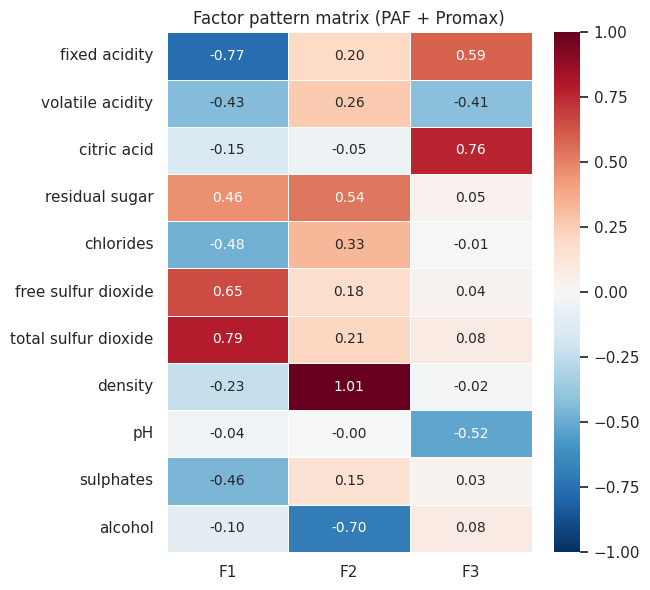

In [63]:
# Heatmap of the pattern matrix
plt.figure(figsize=(6.5, 6))
sns.heatmap(pattern_df, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, linewidths=.5)
plt.title('Factor pattern matrix (PAF + Promax)')
plt.tight_layout()
plt.show()

## Step 6. Naming the factors and how they relate to wine color

In [64]:
# Which variables define each factor (|loading| >= .40)?
for f in factor_names:
    col = pattern_df[f]
    pos = col[col >= .40].sort_values(ascending=False)
    neg = col[col <= -.40].sort_values()
    print(f'{f}  (+) ' + ', '.join(f'{v} ({x:.2f})' for v, x in pos.items()))
    print(f'    (-) ' + ', '.join(f'{v} ({x:.2f})' for v, x in neg.items()))

F1  (+) total sulfur dioxide (0.79), free sulfur dioxide (0.65), residual sugar (0.46)
    (-) fixed acidity (-0.77), chlorides (-0.48), sulphates (-0.46), volatile acidity (-0.43)
F2  (+) density (1.01), residual sugar (0.54)
    (-) alcohol (-0.70)
F3  (+) citric acid (0.76), fixed acidity (0.59)
    (-) pH (-0.52), volatile acidity (-0.41)


Mean factor score by color:


,F1,F2,F3
color,,,
Red,-1.42,0.52,-0.66
White,0.46,-0.17,0.22


F1: Cohen's d (Red - White) = -3.97
F2: Cohen's d (Red - White) = 0.60
F3: Cohen's d (Red - White) = -1.11


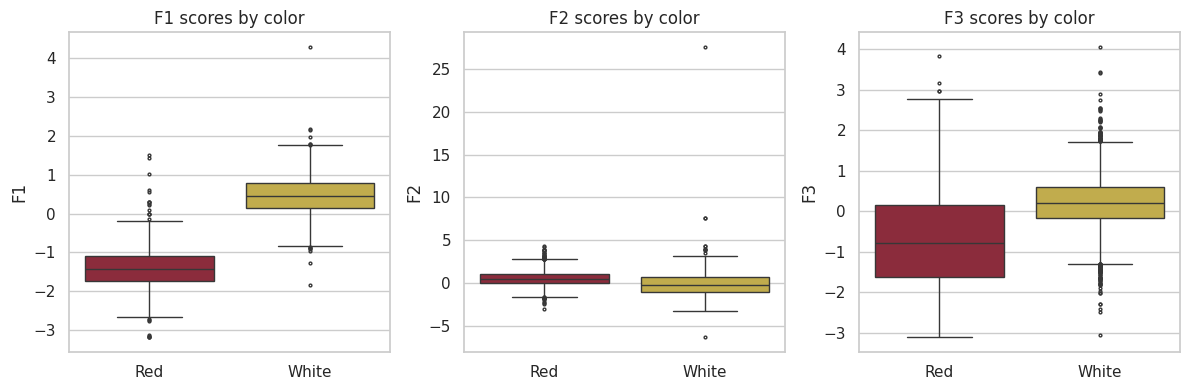

In [66]:
# Factor scores (regression method) and differences between red and white wines
weights = np.linalg.inv(R) @ (pattern @ phi)
scores = pd.DataFrame(Z.values @ weights, columns=factor_names)
scores['color'] = wine['color'].values

print('Mean factor score by color:'); display(scores.groupby('color')[factor_names].mean().round(2))
for f in factor_names:
    a, b = scores.loc[scores.color == 'Red', f], scores.loc[scores.color == 'White', f]
    d = (a.mean() - b.mean()) / np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(scores)-2))
    print(f"{f}: Cohen's d (Red - White) = {d:.2f}")

fig, axes = plt.subplots(1, k, figsize=(4 * k, 4))
for ax, f in zip(axes, factor_names):
    sns.boxplot(data=scores, x='color', y=f, hue='color', palette=colors, ax=ax, fliersize=2, legend=False)
    ax.set_title(f'{f} scores by color'); ax.set_xlabel('')
plt.tight_layout()
plt.show()

## Step 7. Robustness checks
I check whether the factors survive (a) a log transformation of the skewed variables, (b) removing density (the Heywood/KMO problem), (c) removing the red/white mean difference, and (d) a 4-factor solution.
Similarity of factors is measured with **Tucker's congruence coefficient** (|φ| above about .95 = the factors are essentially identical; .85 to .94 = fairly similar).

In [67]:
def run_efa(data, k_use):
    # standardize, PAF, Promax; returns the pattern matrix (variables x factors) and communalities
    Zd = (data - data.mean()) / data.std()
    Rd = np.corrcoef(Zd.values, rowvar=False)
    Ld, h2d, _ = paf(Rd, k_use)
    Pd, phid = promax(Ld)
    Pd, phid = tidy(Pd, phid, h2d)
    return pd.DataFrame(Pd, index=data.columns, columns=[f'F{i}' for i in range(1, k_use + 1)]), h2d, phid

def tucker(a, b):
    return (a * b).sum() / np.sqrt((a ** 2).sum() * (b ** 2).sum())

def compare_to_main(other, label):
    common = [v for v in vars11 if v in other.index]
    rows = {}
    for f in factor_names:
        sims_ = {g: tucker(pattern_df.loc[common, f].values, other.loc[common, g].values) for g in other.columns}
        best = max(sims_, key=lambda g: abs(sims_[g]))
        rows[f] = f'{best} ({abs(sims_[best]):.2f})'
    print(f'{label:<38}', rows)

# (a) log-transform skewed variables
skewed = ['residual sugar', 'chlorides', 'sulphates', 'free sulfur dioxide', 'volatile acidity']
X_log = X.copy(); X_log[skewed] = np.log(X_log[skewed])
P_log, h2_log, _ = run_efa(X_log, k)

# (b) without density
P_nod, h2_nod, phi_nod = run_efa(X[vars10], k)

# (c) within-color: subtract each color's mean first
X_within = X - X.groupby(wine['color']).transform('mean')
P_wit, h2_wit, phi_wit = run_efa(X_within, k)

print('Best-matching factor (Tucker congruence) for each main factor:')
compare_to_main(P_log, '(a) log-transformed variables')
compare_to_main(P_nod, '(b) without density')
compare_to_main(P_wit, '(c) color effect removed')

Best-matching factor (Tucker congruence) for each main factor:
(a) log-transformed variables          {'F1': 'F1 (0.98)', 'F2': 'F2 (0.99)', 'F3': 'F3 (0.97)'}
(b) without density                    {'F1': 'F1 (0.77)', 'F2': 'F1 (0.65)', 'F3': 'F3 (1.00)'}
(c) color effect removed               {'F1': 'F3 (0.66)', 'F2': 'F1 (0.95)', 'F3': 'F2 (0.97)'}


In [68]:
# Side-by-side loadings for the three variants
variants = pd.concat({'Main': pattern_df, 'Log': P_log, 'No density': P_nod, 'Within color': P_wit}, axis=1)
variants.round(2)

Main               Log             No density             Within color            
                        F1    F2    F3    F1    F2    F3         F1    F2    F3           F1    F2    F3
fixed acidity        -0.77  0.20  0.59 -0.69  0.21  0.72      -0.23  0.55  0.54         0.20  0.70 -0.18
volatile acidity     -0.43  0.26 -0.41 -0.44  0.25 -0.26      -0.14  0.51 -0.38         0.20 -0.36 -0.12
citric acid          -0.15 -0.05  0.76 -0.02 -0.02  0.66       0.02  0.03  0.72        -0.10  0.75  0.15
residual sugar        0.46  0.54  0.05  0.53  0.48  0.03       0.61  0.00  0.06         0.67 -0.04  0.09
chlorides            -0.48  0.33 -0.01 -0.46  0.50 -0.02       0.04  0.69 -0.01         0.17  0.13  0.06
free sulfur dioxide   0.65  0.18  0.04  0.78  0.11 -0.07       0.63 -0.24 -0.01        -0.06 -0.00  0.79
total sulfur dioxide  0.79  0.21  0.08  0.87  0.22 -0.01       0.78 -0.29  0.03         0.18 -0.01  0.71
density              -0.23  1.01 -0.02 -0.07  0.99  0.07        NaN   NaN   NaN         1.01  0.06 -0.01
pH                   -0.04 -0.00 -0.52 -0.12  0.01 -0.52      -0.18 -0.01 -0.48        -0.18 -0.45  0.14
sulphates            -0.46  0.15  0.03 -0.40  0.19  0.02      -0.16  0.42  0.04        -0.09  0.19  0.17
alcohol              -0.10 -0.70  0.08 -0.21 -0.70  0.05      -0.59 -0.43  0.06        -0.66  0.05 -0.07

In [69]:
# (d) The 4-factor alternative
P4_raw, phi4_raw = promax(paf(R, 4)[0])
h2_4 = paf(R, 4)[1]
P4, phi4 = tidy(P4_raw, phi4_raw, h2_4)
f4 = pd.DataFrame(P4, index=vars11, columns=['F1', 'F2', 'F3', 'F4'])
f4['h2'] = h2_4
print('4-factor Promax pattern matrix:'); display(f4.round(2).style.map(highlight, subset=['F1', 'F2', 'F3', 'F4']))
print('Factor correlations:'); display(pd.DataFrame(phi4, index=f4.columns[:4], columns=f4.columns[:4]).round(2))

4-factor Promax pattern matrix:


,F1,F2,F3,F4,h2
fixed acidity,-0.480000,0.250000,0.550000,0.190000,0.670000
volatile acidity,-0.380000,0.280000,-0.370000,0.160000,0.470000
citric acid,0.200000,-0.110000,0.770000,0.230000,0.570000
residual sugar,0.260000,0.580000,-0.000000,-0.310000,0.610000
chlorides,-0.020000,0.240000,0.060000,0.560000,0.400000
free sulfur dioxide,0.820000,0.040000,0.050000,0.120000,0.590000
total sulfur dioxide,0.870000,0.090000,0.080000,0.000000,0.800000
density,-0.030000,0.990000,-0.020000,0.180000,1.000000
pH,0.080000,-0.080000,-0.470000,0.290000,0.350000
sulphates,0.140000,0.000000,0.130000,0.750000,0.430000


Factor correlations:


,F1,F2,F3,F4
F1,1.00,0.10,0.14,-0.63
F2,0.10,1.00,0.22,0.08
F3,0.14,0.22,1.00,-0.21
F4,-0.63,0.08,-0.21,1.00


## Summary of results and interpretation

### Factorability (Step 1)
Bartlett's test is significant (χ²(55) = 37,094.6, p < .001) and 16 of 55 correlations are ≥ .30, so there are relationships to explain.
The overall **KMO is .405** (below .50), and five variables have individual MSA below .50: fixed acidity (.28), residual sugar (.29), density (.30), pH (.21) and alcohol (.27).
The cause is density (R² = .94 with the other variables); without it KMO is .66. **Conclusion: the matrix is only marginally factorable.** There is clear shared structure, but part of it is a near-linear dependency rather than distinct latent variables, which is why the solution has some imperfections noted below.

### Number of factors (Step 2)
Kaiser (λ > 1), standard parallel analysis and the scree plot all point to **3 factors** (eigenvalues 3.03, 2.49, 1.56; the 4th is 0.97 against a random benchmark of 1.03). Parallel analysis on the reduced matrix is too liberal at n = 6,497 (it would keep 7).
A 5-factor solution produces a second improper case (pH becomes a one-variable factor), a sign of over-extraction. A 4-factor solution fits better (RMSR .04 vs .055) but its fourth factor has only two salient variables.
Three factors are retained, consistent with the three components in Part C, and they account for **53.1%** of the total variance (23.3%, 19.9%, 9.8%). This is lower than the 64.4% from PCA because EFA models only the *shared* variance.

### Method and rotation (Steps 3–4)
**Principal Axis Factoring** was used because Maximum Likelihood assumes multivariate normality, which these skewed, heavy-tailed data clearly violate; PAF needs no distributional assumption. Density's communality exceeded 1 (a Heywood case), so communalities were capped at .995.
(As a cross-check, MinRes extraction from the `factor_analyzer` package agreed with this PAF solution to within about .04 on all communalities except density.)
**Promax (oblique)** was chosen because chemical dimensions of wine are expected to correlate. The factor correlations confirm this: F1–F3 = .35, F2–F3 = .24, F1–F2 = .05. The F1–F3 correlation exceeds the .32 rule of thumb, so an orthogonal rotation would have forced a false independence.

### Final solution (Step 5–6)
| Factor | Salient loadings (pattern matrix, \|λ\| ≥ .40) | Name |
|---|---|---|
| **F1** (23.3%) | total SO₂ (.79), free SO₂ (.65), residual sugar (.46) vs. fixed acidity (−.77), chlorides (−.48), sulphates (−.46), volatile acidity (−.43) | **Preservation (sulfur dioxide) vs. acidity-and-salts profile** (wine-style / red–white contrast) |
| **F2** (19.9%) | density (1.01), residual sugar (.54) vs. alcohol (−.70) | **Density–sweetness–alcohol (body) factor** |
| **F3** (9.8%) | citric acid (.76), fixed acidity (.59) vs. pH (−.52), volatile acidity (−.41) | **Acidity factor** (fixed/citric acid vs. pH) |

Factor scores confirm the meaning: F1 separates red from white wines enormously (Cohen's d = −3.97, red ≈ −1.42, white ≈ +0.46), F3 moderately (d = −1.11, reds more acidic with higher pH-type scores), and F2 modestly (d = 0.60).

**Diagnostic flags**
- *Clean, single-factor variables:* citric acid, free SO₂, total SO₂, alcohol.
- *Cross-loading:* fixed acidity (F1 −.77, F3 .59), volatile acidity (F1 −.43, F3 −.41), residual sugar (F2 .54, F1 .46) and chlorides (F1 −.48, F2 .33).
- *Low communality (h² < .30):* sulphates (.22) and pH (.29), so the three factors explain little of their variance (uniqueness .78 and .71).
- *Heywood case:* density (h² capped at .995, loading 1.01 on F2), so F2 is essentially "density", with alcohol and sugar attached.
- *Weak loadings:* no variable is without a salient loading.

### Robustness (Step 7)
- **Log-transformed variables:** all three factors are essentially unchanged (congruence .97 to .99).
- **Without density:** F3 (acidity) is reproduced exactly (congruence 1.00), but F1 splits into a sulfur-dioxide–sugar–(low-alcohol) factor and a separate acids-and-salts factor (fixed/volatile acidity, chlorides, sulphates).
- **Red/white difference removed:** the density–sugar–alcohol factor (.95) and the acidity factor (.97) reappear, but the bipolar F1 does not: within a color, sulfur dioxide forms its own factor and the acid-and-salts contrast disappears.
- **4-factor alternative:** splits F1 into a sulfur dioxide factor (free .82, total .87) and a salts factor (sulphates .75, chlorides .56), with a strong correlation between them (−.63).

So **F2 and F3 are stable; F1 is partly a red-versus-white contrast** (bipolar and heterogeneous), and a careful reader should treat it as two related ideas, preservation and acid/salt composition, rather than a single clean construct.

## Answer to the research question

**The 11 physicochemical measurements are explained by three correlated latent dimensions** (about 53% of the variance):
1. **Preservation vs. acidity/salts profile (F1).** Sulfur dioxide (free and total) and sugar on one side, and fixed/volatile acidity, chlorides and sulphates on the other. This dimension mostly captures the contrast between white and red wine styles.
2. **Density–sweetness–alcohol, the "body" of the wine (F2).** Dissolved sugar raises density and alcohol lowers it, so these three variables move together, a direct result of how much sugar was fermented into alcohol.
3. **Acidity (F3).** Citric and fixed acid rise as pH falls, with less volatile acidity.

**Limitations:** the matrix is only marginally factorable (KMO = .405, because of density); density is a Heywood case; F1 is heterogeneous and partly driven by wine color; sulphates and pH are poorly explained (h² = .22 and .29); and 47% of the variance is unique or error. A 4-factor solution (separating sulfur dioxide from a salts/sulphates factor) is a defensible alternative if more detail is wanted.

## 8. Part E – Integrated Interpretation

This section integrates the findings from Multivariate Analysis of Variance (MANOVA), Principal Component Analysis (PCA), and Exploratory Factor Analysis (EFA) to develop a comprehensive understanding of the physicochemical characteristics of Portuguese *Vinho Verde* wines. Each method provides a different perspective: MANOVA identifies differences between red and white wines, PCA summarizes the major dimensions of variation, and EFA investigates the underlying patterns of shared variation among the chemical measurements.

The combined dataset contains 6,497 observations, comprising 1,599 red wines and 4,898 white wines, with 11 physicochemical variables used in PCA and EFA. MANOVA, however, uses six selected physicochemical variables: fixed acidity, volatile acidity, residual sugar, chlorides, sulphates, and total sulfur dioxide. This difference in variable selection should be considered when comparing the findings across methods.

### 8.1 MANOVA: Group Differentiation

**Research question: What distinguishes red and white wines?**

The MANOVA results demonstrate that red and white wines differ significantly in their overall physicochemical profiles. The multivariate test produced Wilks' Lambda = 0.237, Pillai's Trace = 0.763, and F(6, 6490) = 3481.81, with p < 0.001. Therefore, the null hypothesis that the two wine groups have equal multivariate mean vectors for the six selected variables is rejected.

Wilks' Lambda indicates substantial separation between the group mean vectors, while Pillai's Trace supports the same conclusion. The reported multivariate effect-size measure is 0.763, indicating a strong association between wine color and the combined response variables under the notebook's stated effect-size interpretation. The group-centroid Mahalanobis distance is 4.16, further indicating substantial multivariate separation.

The follow-up univariate ANOVAs identify the variables associated with this difference. All six variables are statistically significant after Bonferroni adjustment, using an adjusted significance level of approximately 0.0083.

| Physicochemical variable | Red wine mean | White wine mean | F-statistic | Cohen's d (red − white) |
|---|---:|---:|---:|---:|
| Total sulfur dioxide | 46.468 | 138.361 | 6252.80 | −2.278 |
| Volatile acidity | 0.528 | 0.278 | 4829.32 | 2.002 |
| Chlorides | 0.087 | 0.046 | 2315.83 | 1.386 |
| Fixed acidity | 8.320 | 6.855 | 2016.51 | 1.293 |
| Sulphates | 0.658 | 0.490 | 2021.71 | 1.295 |
| Residual sugar | 2.539 | 6.391 | 899.77 | −0.864 |

*All six comparisons have p < 0.001 and remain significant under the Bonferroni adjustment.*

Total sulfur dioxide exhibits the largest standardized group difference among the selected variables, with white wines having a substantially higher mean concentration. Volatile acidity is also a major differentiator, with red wines having a higher mean. Red wines additionally show higher mean chlorides, fixed acidity, and sulphates, whereas white wines have higher residual sugar.

These differences suggest that wine color is associated with distinct chemical profiles involving sulfur dioxide concentration, acidity, salts, and sugar content. The results do not establish that color itself causes these chemical differences; rather, color identifies two groups with markedly different observed physicochemical characteristics.

The interpretation is supported by the notebook's robustness checks. Pillai's Trace remains significant after log-transforming the selected variables, removing duplicate observations, and excluding flagged multivariate outliers. The permutation test also produces p < 0.001. Thus, the evidence of group separation is not limited to the original analysis.

However, the assumptions require consideration. Box's M test is highly significant, indicating unequal covariance matrices, and Mardia's tests indicate departures from multivariate normality. The unequal group sizes—1,599 red wines versus 4,898 white wines—make these departures particularly relevant. The use of Pillai's Trace, Welch tests, and robustness checks provides additional evidence, although it does not eliminate every limitation.

### 8.2 PCA: Major Dimensions of Variation

**Research question: What are the major dimensions of variation among the physicochemical measurements?**

PCA was conducted on standardized versions of all 11 physicochemical variables. Standardization is important because the variables are measured on different scales. Without standardization, total sulfur dioxide would dominate the first component because of its much larger numerical variance, and the analysis would primarily reflect measurement units rather than the relationships among variables.

The analysis retained three principal components. Their eigenvalues and proportions of explained variance are summarized below.

| Principal component | Eigenvalue | Variance explained | Cumulative variance |
|---|---:|---:|---:|
| PC1 | 3.030 | 27.5% | 27.5% |
| PC2 | 2.494 | 22.7% | 50.2% |
| PC3 | 1.556 | 14.1% | 64.4% |

Together, the three components explain **64.4% of the total variance** in the standardized physicochemical measurements. The retention decision is supported by the Kaiser criterion, the scree plot, and parallel analysis, all of which indicate three components.

Each principal component is a linear combination of the original standardized variables. The first component maximizes the variance captured by a single linear combination; the second captures the greatest remaining variance subject to being orthogonal to the first; and the third captures the greatest remaining variance subject to being orthogonal to the first two.

The component loadings help explain the dimensions represented by these combinations.

**PC1: Sulfur dioxide and chemical-composition contrast.** The largest positive loadings are total sulfur dioxide (0.848) and free sulfur dioxide (0.750), followed by residual sugar (0.602). Strong negative loadings include volatile acidity (−0.663), sulphates (−0.512), chlorides (−0.505), and fixed acidity (−0.416). PC1 therefore represents a broad contrast between sulfur-dioxide and sugar measurements on one side and several acidity-and-salt-related measurements on the other. This axis also reflects the substantial red–white difference identified by MANOVA.

**PC2: Density, sugar, and alcohol balance.** Density (0.922), residual sugar (0.521), and fixed acidity (0.531) load positively, whereas alcohol has a strong negative loading (−0.734). This component captures a major pattern in which density and residual sugar vary in opposition to alcohol concentration. It can be interpreted descriptively as a density–sugar–alcohol dimension, although it should not be treated as a direct measurement of perceived body or sweetness.

**PC3: Acidity-related variation.** Citric acid (0.737) and fixed acidity (0.542) load positively, while pH loads negatively (−0.568). This pattern is consistent with an acidity-related dimension because pH and acid concentrations describe related but distinct chemical properties.

These interpretations are consistent with the notebook's exploratory findings. In particular, density and alcohol have a strong negative correlation, while density and residual sugar have a positive correlation. The first three components therefore provide a useful reduced representation of the relationships among the 11 variables without requiring the original variables to be interpreted independently.

The PCA results also show that red and white wines are strongly separated along PC1. The reported Cohen's d for PC1 is −3.39 when calculated as red minus white, indicating a very large standardized difference in component scores. PC2 shows a smaller difference (d = 0.68), while PC3 shows little group separation (d = −0.20). This supports the interpretation that the dominant axis of variation partly reflects the distinction between the two wine colors.

Although the three-component solution captures a substantial proportion of total variance, 35.6% remains outside the retained components. The reduced representation is therefore informative but does not preserve every feature of the original chemical measurements.

### 8.3 EFA: Underlying Latent Constructs

**Research question: What latent factors appear to explain the relationships among the variables?**

EFA was conducted using Principal Axis Factoring (PAF) with Promax oblique rotation. Unlike PCA, EFA seeks to explain the correlations among observed variables through a smaller number of underlying latent factors. Promax rotation allows the factors to correlate, which is appropriate when the chemical dimensions of wine may overlap.

The analysis retained three factors, supported by the eigenvalue criterion, scree plot, parallel analysis, and interpretability of the solution. The three factors account for approximately 53.1% of the variance according to the notebook's extraction summary: F1 explains 23.3%, F2 explains 19.9%, and F3 explains 9.8%.

The following factor names are interpretive labels based on the observed loading patterns; they are not directly measured chemical properties.

**Factor 1: Preservation versus acidity-and-salts profile.**

F1 has strong positive loadings for total sulfur dioxide (0.79) and free sulfur dioxide (0.65). Residual sugar also loads positively (0.46). Fixed acidity (−0.77), chlorides (−0.48), sulphates (−0.46), and volatile acidity (−0.43) load negatively.

This factor represents a contrast between sulfur-dioxide-related measurements and a group of acidity-and-salt-related measurements. Sulfur dioxide is relevant to wine preservation because it can contribute to microbial control and oxidation management. However, the mixed loading pattern suggests that this factor does not represent a single, chemically pure preservation construct. It also reflects the strong differences between red and white wines, so it should be interpreted as a combined preservation and wine-composition contrast.

**Factor 2: Density–sweetness–alcohol balance.**

F2 is characterized by density (1.01), residual sugar (0.54), and alcohol (−0.70). This pattern is consistent with a relationship among density, residual sugar, and alcohol concentration. Higher residual sugar can contribute to density, while alcohol has a different relationship with density. The factor therefore captures a useful compositional balance, but it should not be interpreted as a direct measure of sweetness, body, or fermentation completeness.

Density requires particular caution because its estimated communality was capped at 0.995 after the analysis produced a Heywood case. Its loading of 1.01 is an improper factor-model result rather than a physically meaningful correlation exceeding one. The factor is consequently less stable and should be interpreted as a density-dominated dimension.

**Factor 3: Acidity factor.**

F3 has positive loadings for citric acid (0.76) and fixed acidity (0.59), with negative loadings for pH (−0.52) and volatile acidity (−0.41). The positive association of acid concentrations and negative loading of pH are broadly consistent with an acidity-related dimension. Nevertheless, volatile acidity does not behave identically to fixed acidity or citric acid, which is reflected in its cross-loading.

The three-factor solution therefore suggests that the observed correlations can be summarized through a sulfur-dioxide and composition contrast, a density–sugar–alcohol balance, and an acidity-related dimension.

The factorability diagnostics indicate that the EFA findings must be treated cautiously. Bartlett's test is significant, with χ²(55) = 37,094.6 and p < 0.001, indicating that the correlation matrix is not an identity matrix. However, the overall KMO value is only 0.405, below the usual 0.50 guideline. Density is almost entirely predictable from the other variables, contributing to the low KMO and the Heywood case.

Furthermore, sulphates and pH have communalities below 0.30, indicating that the retained factors explain relatively little of their variance. Several variables cross-load on more than one factor. The EFA is therefore useful for exploratory interpretation, but the factors should not be treated as definitive or uniquely established chemical constructs.

### 8.4 Comparison of PCA and EFA

PCA and EFA both reduce the complexity of the 11 physicochemical measurements, but they differ in their statistical objectives.

**Conceptual differences.** PCA decomposes total variance into orthogonal principal components. It accounts for both shared variation and variable-specific variation, making it useful for data reduction and visualization. EFA instead models the covariance or correlation structure through common factors and variable-specific uniqueness. It focuses on the variation shared among variables rather than attempting to represent all observed variance.

This distinction explains why PCA retains 64.4% of the total variance in its three-component solution, whereas the EFA extraction summary reports approximately 53.1%. The percentages describe different aspects of the data and should not be treated as directly equivalent measures of model quality.

**Structural similarities and differences.** Both methods identify related patterns involving sulfur dioxide, density, residual sugar, alcohol, and acidity. However, PCA loadings describe the relationship between each observed variable and a component, while EFA pattern loadings describe the variable's relationship with a latent factor after accounting for the model's factor structure.

PCA components are orthogonal by construction, whereas Promax-rotated EFA factors may correlate. In the EFA solution, the correlation between F1 and F3 is approximately 0.35, F2 and F3 correlate at 0.24, and F1 and F2 correlate at 0.05. These results indicate that the extracted factors are not entirely independent.

The EFA factor labels also differ from the PCA interpretations because the methods optimize different objectives and use different loading structures. The labels should therefore be treated as complementary interpretations rather than as interchangeable component and factor names.

**Variables that emerge across both methods.** Several variables consistently contribute to the reduced representations:

- **Total and free sulfur dioxide:** Both have strong positive loadings on PC1 and F1, identifying sulfur dioxide as a major source of variation.
- **Density, residual sugar, and alcohol:** These variables contribute strongly to PC2 and F2, reflecting a related compositional dimension.
- **Fixed acidity, citric acid, and pH:** These variables help define PC3 and F3, supporting an acidity-related interpretation.
- **Volatile acidity, chlorides, and sulphates:** These variables contribute to PC1 and F1, particularly in the contrast between sulfur-dioxide-related measurements and acidity-and-salt-related characteristics.

The similarity is meaningful, but it is not complete. For example, fixed acidity contributes to multiple components and factors, while sulphates have a relatively low EFA communality. Density is strongly represented in both methods, but its Heywood case makes the EFA interpretation particularly uncertain.

The robustness checks further clarify the comparison. PCA loadings remain highly similar after log transformation, with absolute loading correlations of 0.95–0.99 for the first three components. EFA factors are also highly similar after log transformation, with Tucker congruence coefficients of 0.97–0.99. However, removing density changes the EFA structure, and removing the red–white mean difference substantially changes F1. Thus, some shared patterns are robust to transformations, while others depend on density and wine-color differences.

### 8.5 Substantive Domain Interpretation

Taken together, the findings show that Portuguese *Vinho Verde* wines exhibit substantial physicochemical variation that can be organized around several related chemical profiles.

First, preservation-related measurements are a major source of variation. Free and total sulfur dioxide are strongly correlated and dominate the first PCA component and the first EFA factor. Their substantially higher means in white wines suggest differences in the sulfur-dioxide profiles of the two wine groups. These results are consistent with the role of sulfur dioxide in wine preservation, but the observational data do not identify the winemaking decisions responsible for the differences.

Second, acidity and related chemical measurements distinguish the two groups. Red wines have higher mean fixed acidity, volatile acidity, chlorides, and sulphates in the selected MANOVA follow-up results. The PCA and EFA loading patterns also identify relationships among fixed acidity, citric acid, volatile acidity, and pH. These variables describe different aspects of wine chemistry and should not be treated as interchangeable measures of a single acidity property.

Third, residual sugar, density, and alcohol form another important dimension. White wines have a higher mean residual sugar concentration in the MANOVA follow-up analysis, and the PCA and EFA both identify a strong relationship between density, residual sugar, and alcohol. This is consistent with the chemical fact that dissolved sugar and alcohol are associated with density in different ways. However, these measurements alone do not establish the perceived sweetness, body, or sensory balance of a wine.

Fourth, the strong red–white separation demonstrates that wine color is associated with a broad pattern of chemical differences rather than a single distinguishing variable. MANOVA identifies a significant multivariate difference, while PCA shows that PC1 separates the two groups strongly. EFA likewise indicates that the first factor partly reflects the red–white contrast. The pooled multivariate structure therefore combines general relationships among chemical variables with differences between wine categories.

Finally, these analyses concern physicochemical characteristics rather than sensory quality itself. Although the dataset includes a quality score, the three principal multivariate analyses focus on chemical measurements. Consequently, the results do not establish which chemical profile produces a higher-quality wine or how consumers perceive the wines. Establishing those relationships would require a separate analysis that explicitly incorporates sensory quality and carefully accounts for other relevant variables.

Overall, the integrated results suggest that sulfur dioxide, acidity-related measurements, and the density–sugar–alcohol balance are central dimensions of variation in the dataset. These dimensions provide a useful descriptive framework for understanding the chemical profiles of red and white *Vinho Verde* wines, while leaving the causal mechanisms and sensory implications unresolved.

### 8.6 Methodological Limitations

Several limitations affect the interpretation of the integrated results.

**1. Observational nature of the data.**

The dataset contains observed wine measurements rather than results from a controlled experiment. Therefore, the analyses identify associations and group differences but cannot establish causal relationships. For example, the higher mean sulfur dioxide concentration in white wines does not demonstrate that wine color itself causes higher sulfur dioxide levels. Differences in production methods, grape varieties, processing, storage, or other unobserved characteristics may contribute to the observed patterns. Similarly, the latent factors identified by EFA describe statistical relationships and do not establish specific underlying winemaking mechanisms.

**2. Class imbalance and differences between groups.**

The dataset contains 4,898 white wines and 1,599 red wines, meaning the white-wine group is approximately three times larger. This imbalance does not automatically invalidate MANOVA or PCA, but it can affect the influence of each group on pooled estimates and makes unequal covariance structures more important. Box's M test is significant, and the notebook reports unequal variances for the selected MANOVA variables. The use of Pillai's Trace and robustness checks helps evaluate the stability of the group comparison. Nevertheless, the pooled PCA and EFA solutions are influenced by the relative representation of each group and may partly describe differences between red and white wines rather than relationships that hold within each color.

**3. Outliers, skewness, and heteroskedasticity.**

Several variables exhibit substantial right skewness and extreme observations. The notebook identifies unusual values in variables such as chlorides, residual sugar, and sulfur dioxide. These observations can affect covariance estimates, correlations, principal-component loadings, and factor extraction. Unequal variances between wine groups can also affect the interpretation of the MANOVA follow-up tests. Log-transformation and outlier-removal sensitivity analyses provide useful checks, and the principal findings remain significant in the MANOVA robustness analysis. However, robustness does not mean that every loading or factor interpretation is unaffected by extreme observations.

**4. Multicollinearity and the EFA Heywood case.**

Some physicochemical measurements share strong relationships. Density, residual sugar, and alcohol are particularly related, while free and total sulfur dioxide are also strongly correlated. These dependencies can make it difficult to separate distinct underlying dimensions. The overall KMO value of 0.405 indicates that